# Introduction
La légende urbaine veut que plus de 5 millions de rats vivent à Paris, ce qui équivaut à plus d'un rat et demi par habitant. Paris se placerait alors en quatrième position des villes avec le plus de rats, derrière Londres, New-York et Deshnoke (en Inde). Ce chiffre de 5 millions, largement répété mais dont la source est difficile à établir, alimente l'association d'idées entre Paris et les rongeurs dans un sens plus négatif que le film _Ratatouille_ sorti en 2007. Face à cela, depuis 2017, la Ville de Paris renforce ses actions anti-rats avec un plan d'actions. Pour limiter la prolifération des rongeurs, la municipalité a multiplié ses interventions et s'appuie sur une application nommée "Dans ma rue" qui permet à chacun de signaler des dégradations dans l'espace public, ainsi que la présence de rats. 

La présence de rats étant un vrai fléau pour Paris et un enjeu actuel, nous avons choisi de nous pencher sur ce sujet pour savoir s'il était possible de "prédire" la présence d'un rat à un moment donné, à un lieu donné. Il nous a semblé raisonnable d'élargir ce que nous avons trouvé dans la base de données initiale (Dans Ma Rue) pour y inclure des variables qui nous semblent être pertinentes pour prédire la présence de rats. L'imaginaire du rat de gouttière qui aime les environnements humides et les poubelles nous a aiguillé dans la sélection de ces angles d'analyse complémentaires. En plus des dates et des coordonées GPS des signalements de rats, nous  nous sommes concentrés sur des données météorologiques et géographiques plus adaptées à l'espace urbain parisien. A elles seules, ces variables suffisent-elles à prédire le prochain signalement de rat ? 

Pour répondre à cette question, nous procédons en quatre temps. La partie 1 présente les signalements de rats de Dans Ma Rue entre 2012 et 2025 : leur nettoyage, leur répartition selon les variables de la base et leur évolution dans le temps. La partie 2 enrichit ces données avec des variables géographiques (surfaces d'eau de l'IGN, espaces verts, grille de carreaux de 200 m), puis les décrit : distance à l'eau, foyers de signalements repérés par DBSCAN, taux de signalement et niveau de vie par arrondissement. La partie 3 étudie plus en détail le lien entre les signalements, les espaces verts et les composteurs. La partie 4 estime deux modèles linéaires : le premier explique le nombre de signalements par arrondissement et par jour selon la météo et la saison, le second le nombre de signalements par carreau de 200 m selon la géographie. Les annexes regroupent le test d'autres paramètres pour DBSCAN, un exemple de prédiction, les variables non retenues et les instructions pour reproduire les résultats.

## Fichiers du dépôt

Le dépôt GitHub contient les fichiers python suivants :

- `data_preparation.py` : lit les fichiers annuels de Dans Ma Rue (2012 à 2025), garde les signalements de rats et de souris, harmonise les colonnes et écrit `clean_rats.csv`.
- `fichier_meteo.py` : réunit l'historique météo de Paris de 2012 à 2025, ajoute des moyennes de température et écrit `clean_meteo.csv`.
- `statistiques_descriptives.py` : premières statistiques sur les signalements (proportions, extrêmes, évolution par année, par mois et par saison).
- `analyse_espaces_verts.py` : compare la position des signalements par rapport aux espaces verts et aux composteurs à celle de points tirés au hasard dans Paris (partie 3).
- `eau.py` : télécharge les surfaces d'eau de l'IGN (Seine, Marne, canaux) et calcule la distance d'un point à l'eau.
- `grille.py` : découpe Paris en carreaux de 200 m et rattache chaque point à son carreau.
- `DBSCAN.py` : regroupe les signalements proches en foyers avec l'algorithme DBSCAN (partie 2.4).
- `prediction.py` : modèle temporel, signalements par arrondissement et par jour (partie 4.1).
- `modele_spatial.py` : modèle spatial, signalements par carreau de 200 m (partie 4.2).
- `app.py` : application Streamlit en trois onglets : prévision du jour par arrondissement, zones à risque par carreau, foyers DBSCAN par année.


In [1]:
import io
import os
import json
import zipfile

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import osmnx as ox
import pandas as pd
import requests
import shapely
import statsmodels.api as sm
from matplotlib.colors import LogNorm
from scipy import stats
from scipy.spatial import cKDTree
from shapely.geometry import shape
from sklearn.neighbors import NearestNeighbors

from DBSCAN import RAYON_TERRE_M, regrouper_points
from eau import (
    COS_PARIS,
    DOSSIER_DONNEES,
    FICHIER_EAU,
    NATURES_GARDEES,
    ajouter_distance_eau,
    charger_cours_d_eau,
    en_metres,
)
from grille import TAILLE_CARREAU_M, URL_ARRONDISSEMENTS, creer_carreaux, rattacher_aux_carreaux
from modele_spatial import VARIABLES as VARIABLES_SPATIALES
from modele_spatial import (
    TYPE_BOIS,
    compter_par_carreau,
    decrire_carreaux,
    estimer_modele_spatial,
    telecharger_espaces_verts,
    unir_en_metres,
)
from prediction import (
    ARRONDISSEMENT_REFERENCE,
    CIBLE,
    DATE_DEBUT,
    DATE_DEBUT_TEST,
    FICHIER_METEO,
    FICHIER_RATS,
    SAISON_REFERENCE,
    SEUIL_PLUIE_MM,
    charger_meteo,
    charger_signalements,
    construire_panel,
    estimer_modele,
    evaluer_prevision,
    filtrer_periode,
    predire_risque_par_arrondissement,
    preparer_variables,
    tableau_coefficients,
    tests_joints,
)

# 4 chiffres significatifs : les très petites p-valeurs restent lisibles
pd.set_option("display.float_format", "{:.4g}".format)
# tableaux larges affichés en entier
pd.set_option("display.max_columns", None)
# couleur des histogrammes et des diagrammes en barres
COULEUR = "#1c5cab"
# dossier où la partie 1 enregistre ses figures
os.makedirs("Outputs", exist_ok=True)

# 1. Premières observations
## 1.1. Préparation et nettoyage des données Dans Ma Rue

Avant de commencer, une précision nous semble importante à faire : ici, nous n'étudions que la présence de rats ayant été signalés. Cela peut donc induire des biais que nous ne pouvons pas détecter : en effet, il ne semble pas impossible que les personnes qui signalent davantage des rats partagent des caractéristiques géographiques ou socio-démographiques. 

In [3]:
data2012 = pd.read_csv('données/DMR_2012.csv', sep=";", encoding='utf-8')
data2013 = pd.read_csv('données/DMR_2013.csv', sep=";", encoding='utf-8')
data2014 = pd.read_csv('données/DMR_2014.csv', sep=";", encoding='utf-8')
data2015 = pd.read_csv('données/DMR_2015.csv', sep=";", encoding='utf-8')
data2016 = pd.read_csv('données/DMR_2016.csv', sep=";", encoding='utf-8')
data2017 = pd.read_csv('données/DMR_2017.csv', sep=";", encoding='utf-8')
data2018 = pd.read_csv('données/DMR_2018.csv', sep=";", encoding='utf-8')
data2019 = pd.read_csv('données/DMR_2019.csv', sep=";", encoding='utf-8')
data2020 = pd.read_csv('données/DMR_2020.csv', sep=";", encoding='utf-8')
data2021 = pd.read_csv('données/DMR_2021.csv', sep=";", encoding='utf-8')
data2022 = pd.read_csv('données/DMR_2022.csv', sep=";", encoding='cp1252')
data2023 = pd.read_csv('données/DMR_2023.csv', sep=";", encoding='cp1252')
data2024 = pd.read_csv('données/DMR_2024.csv', sep=";", encoding='utf-8')
data2025 = pd.read_csv('données/DMR_2025.csv', sep=";", encoding='utf-8')

# HARMONISATION DES COLONNES

datas = {f"data20{i}": globals()[f"data20{i}"] for i in range(12, 26)}

for i in range(12, 26):
    # on met tous les noms de colonnes en majuscule
    datas[f"data20{i}"].columns = datas[f"data20{i}"].columns.str.upper()

# Harmonisation des formats date
for nom, data in datas.items():
    # On voir une forte hétérogénéité des formats de date
    dates = pd.to_datetime(data["DATEDECL"], format="mixed", errors="coerce")
    # format="mixed" lit une date JJ/MM/AAAA dont le jour vaut au plus 12 comme MM/JJ (fichiers 2021 à 2025) :
    # MOISDECL, colonne du fichier brut, donne le vrai mois, on échange alors le jour et le mois
    mois_brut = pd.to_numeric(data["MOISDECL"], errors="coerce")
    inverse = dates.dt.month.ne(mois_brut) & dates.dt.day.eq(mois_brut)
    dates_echangees = pd.to_datetime(
        pd.DataFrame({"year": dates.dt.year, "month": dates.dt.day, "day": dates.dt.month}), errors="coerce"
    )
    data["DATEDECL"] = dates.mask(inverse, dates_echangees)
    data["JOURDECL"] = data["DATEDECL"].dt.day

liste_colonnes = ["ID_DMR", "TYPE", "SOUSTYPE", "ADRESSE", "CODE_POSTAL", "VILLE", "ARRONDISSEMENT",
                  "DATEDECL", "ANNEEDECL", "MOISDECL", "JOURDECL", "CONSEILQUARTIER", "X", "Y"]

for i in range(12, 26):
    datas[f"data20{i}"] = datas[f"data20{i}"][liste_colonnes]


######## IDENTIFICATION DES LIGNES SIGNALANT UNE PRESENCE DE RATS

sous_types_pertinents = {}
for i in range(12, 26):
    df = datas[f"data20{i}"]
    sous_types = df["SOUSTYPE"].dropna().unique()
    sous_types_pertinents[f"20{i}"] = [s for s in sous_types if isinstance(s, str) and (" rat" in s.lower() or " rats" in s.lower() or " souris" in s.lower()) and ("ratp" not in s.lower())]

sous_types_pertinents_uniques = []
for s in sous_types_pertinents.values():
    for u in s:
        if u not in sous_types_pertinents_uniques:
            sous_types_pertinents_uniques.append(u)

# on trouve : [' Présence de rats', ' Présence de souris', 
# " Autres problèmes d'animaux et d'insectes : [] Rats sortant des égouts"]

# SELECTION DES LIGNES PERTINENTES SELON LE SOUS TYPE

for i in range(12, 26):
    df = datas[f"data20{i}"]
    datas[f"data20{i}"] = df[df["SOUSTYPE"].isin(sous_types_pertinents_uniques)]

# CONSTRUCTION DU FICHIER PROPRE
data_clean = pd.concat([datas[f"data20{i}"] for i in range(12, 26)])
print(data_clean.sample(n=5))

# retouches finales:

# test présence NaN
na_counts = data_clean.isna().sum()
print(na_counts[na_counts > 0].sort_values(ascending=False))

# conversion en nombres

def to_num(s: pd.Series) -> pd.Series:
    return pd.to_numeric(
        s.astype(str).str.strip().str.replace(",", ".", regex=False),
        errors="coerce",
    )
data_clean["ARRONDISSEMENT"] = to_num(data_clean["ARRONDISSEMENT"])
data_clean["CODE_POSTAL"] = to_num(data_clean["CODE_POSTAL"])
data_clean["X"] = to_num(data_clean["X"]) #X: longitude
data_clean["Y"] = to_num(data_clean["Y"]) #Y: latitude
# vérification de conversion
print(data_clean.dtypes)  # tout va bien

# pour toute colonne, affiche la proptable
for col in data_clean.columns.drop(["ADRESSE", "X", "Y"]):
    print(f"--- {col} ---")
    print(data_clean[col].value_counts(normalize=True, dropna=False).round(5)*100)
    print("____done____")
# les problèmes de type "75116" "75116.0" "75116,0000" sont résolus

# test présence NaN
na_counts = data_clean.isna().sum()
print("na counts", na_counts[na_counts > 0].sort_values(ascending=False))
# aucun NaN n'est apparu


# on regarde le ID_DMR qui apparaît 2 fois, (constaté dans les proptables précédentes)

# print(data_clean.loc[data_clean["ID_DMR"]=="S2017D000601",:])
# c'est bien la même ligne, on vire le dupliqué
print(data_clean.shape)
data_clean = data_clean.drop_duplicates(subset="ID_DMR")
print(data_clean.shape)  # suppression effective

# réunion des valeurs similaires de SOUSTYPE:

# rappel distribution
print(data_clean["SOUSTYPE"].value_counts(normalize=True, dropna=False).round(5)*100)

# on réecrit les catégories
data_clean.loc[data_clean["SOUSTYPE"] == " Présence de rats", "SOUSTYPE"] = "Présence de rats"
data_clean.loc[data_clean["SOUSTYPE"] == " Présence de souris", "SOUSTYPE"] = "Présence de souris"
data_clean.loc[data_clean["SOUSTYPE"].str.contains("égouts", na=False), "SOUSTYPE"] = "Rats sortant des égouts"

# affichage proptable, a-ce fonctionné? oui!
print(data_clean["SOUSTYPE"].value_counts(normalize=True, dropna=False).round(5)*100)


# l'info de VILLE est redondante à celle de ARRONDISSEMENT, on supprime VILLE
data_clean = data_clean.drop(columns=["VILLE"])

# final check:
print(data_clean.dtypes)
print(data_clean.shape)
for col in data_clean.columns.drop(["ADRESSE", "X", "Y"]):
    print(f"--- CHECK FINAL: {col} ---")
    print(data_clean[col].value_counts(normalize=True, dropna=False).round(5)*100)
    print(f"____FIN CHECK FINAL: {col}____")
# tout paraît ok

data_clean.to_csv('données/clean_rats.csv')

              ID_DMR                         TYPE           SOUSTYPE  \
32369   S2015G005198  Arbres, végétaux et animaux   Présence de rats   
724148  G2025F145346  Arbres, végétaux et animaux   Présence de rats   
449058  A2019J055274  Arbres, végétaux et animaux   Présence de rats   
144460  S2020D004885  Arbres, végétaux et animaux   Présence de rats   
292770  A2021E047745  Arbres, végétaux et animaux   Présence de rats   

                                                 ADRESSE  \
32369                       place léon blum, 75011 PARIS   
724148  Jardin Arnaud Beltrame Rue de Béarn, 75003 PARIS   
449058              4 Rue Benjamin Franklin, 75116 PARIS   
144460  40 rue du Commandant René Mouchotte, 75014 PARIS   
292770                      9v avenue Ibsen, 75020 PARIS   

                  CODE_POSTAL     VILLE      ARRONDISSEMENT   DATEDECL  \
32369                   75011  Paris 11                  11 2015-07-28   
724148                7.5e+04  Paris 03                   

## 1.2. Proportion de signalements en fonction des variables étudiées
Pour avoir une première analyse un peu plus fine, regardons la proportion de signalements en fonction des variables.

In [4]:
data = pd.read_csv("données/clean_rats.csv")
# Se familiariser avec les données :
print(data.sample(3))
print(data.dtypes)

      Unnamed: 0        ID_DMR                         TYPE          SOUSTYPE  \
6186      705036  S2021J071132  Arbres, végétaux et animaux  Présence de rats   
2882      150070  A2018I008761  Arbres, végétaux et animaux  Présence de rats   
4894      264616  S2020G013007  Arbres, végétaux et animaux  Présence de rats   

                                         ADRESSE  CODE_POSTAL  ARRONDISSEMENT  \
6186  6 rue du Château des Rentiers, 75013 PARIS    7.501e+04              13   
2882          9 Rue Louis Delaporte, 75020 PARIS    7.502e+04              20   
4894             97 rue de la Santé, 75013 PARIS    7.501e+04              13   

        DATEDECL  ANNEEDECL  MOISDECL  JOURDECL  \
6186  2021-10-26       2021        10        26   
2882  2018-09-10       2018         9        10   
4894  2020-07-07       2020         7         7   

                                 CONSEILQUARTIER     X     Y  
6186                      MASSENA - JEANNE D'ARC 2.371 48.82  
2882               

In [5]:
# Pour chaque colonne où c'est pertinent, on affiche les proportions par groupe
for col in data.columns.drop(["ID_DMR", "DATEDECL", "CODE_POSTAL", "TYPE", "JOURDECL", "ADRESSE", "X", "Y"]):
    print(f"--- {col} ---")
    print(data[col].value_counts(normalize=True, dropna=False).round(5)*100)
    print("____done____")

--- Unnamed: 0 ---
Unnamed: 0
45329     0.027
64286     0.027
30924     0.018
34010     0.018
47201     0.018
           ... 
1906381   0.009
1906617   0.009
1911616   0.009
1913242   0.009
1913376   0.009
Name: proportion, Length: 11013, dtype: float64
____done____
--- SOUSTYPE ---
SOUSTYPE
Présence de rats          94.74
Présence de souris         4.92
Rats sortant des égouts   0.342
Name: proportion, dtype: float64
____done____
--- ARRONDISSEMENT ---
ARRONDISSEMENT
15   9.931
17   8.966
19   8.101
18   8.065
20   7.525
12   7.254
11   6.957
13   5.993
14   5.506
10   5.434
1    4.632
4     4.19
16   4.091
5    3.082
9    2.586
2     1.73
3    1.658
8    1.577
6    1.397
7    1.325
Name: proportion, dtype: float64
____done____
--- ANNEEDECL ---
ANNEEDECL
2023   11.24
2025   11.02
2019   10.93
2022   10.87
2018   9.985
2021    9.75
2017   9.705
2024   9.309
2020   7.389
2016   6.416
2015   1.964
2014    1.19
2013   0.225
2012   0.009
Name: proportion, dtype: float64
____done____
--- M

On voit qu'en grande majorité (à 94,74%), les signalements sont de type "Présence de rats". La présence de souris est très rare et la mention "rats sortant des égouts" est quasiment négligeable. Cela peut-être dû à une méconnaissance, à la fois du rongeur aperçu puis signalé, ainsi qu'à une méconnaissance des catégories proposées par la plateforme. En effet, la proportion de "rats sortant des égouts" semble particulièrement faible alors même que la ville de Paris intervient régulièrement dans les égouts pour dératiser, attestant par là la présence même de rats dans ces lieux. De plus, on peut voir que l'arrondissement le plus infesté (où il y a donc le plus de signalements) de la capitale est le 15e (qui recense 9,93% des signalements alors que le 7ème n'en concentre que 1,33%). A première lecture, on voit aussi que c'est lors des mois d'août, septembre et octobre que les signalements sont les plus nombreux. On peut alors tracer un tableau présentant les moments et les lieux où les signalements ont été plus et moins importants. 

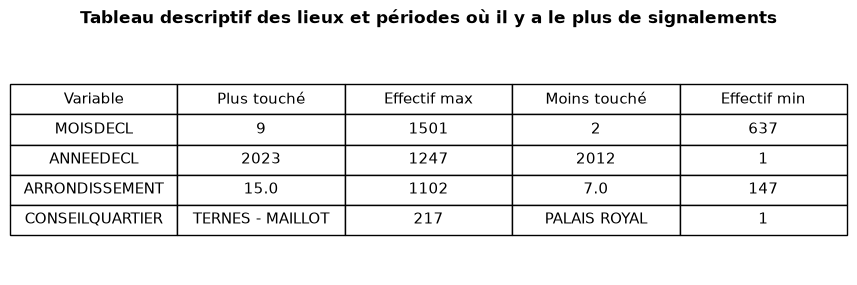

In [7]:
# On veut regarder les mois, années, arrondissements et quartier les plus
# et moins touchés pour davantage de lisibilité. Sous forme de tableau.
colonnes = ['MOISDECL', "ANNEEDECL", 'ARRONDISSEMENT', 'CONSEILQUARTIER']
resultats = []
for col in colonnes:
    groupes = data.groupby(col, dropna=False).size()
    plus = groupes.idxmax()
    moins = groupes.idxmin()
    resultats.append([col, str(plus), int(groupes.max()),
                      str(moins), int(groupes.min())])
maximin = pd.DataFrame(
    resultats,
    columns=['Variable', 'Plus touché', 'Effectif max', 'Moins touché', 'Effectif min'])

fig, ax = plt.subplots(figsize=(6, 3))
ax.axis('off')
ax.set_title("Tableau descriptif des lieux et périodes où il y a le plus de signalements",
             fontweight='bold', pad=15)
tab = ax.table(
    cellText=maximin.values,
    colLabels=maximin.columns,
    cellLoc='center',
    loc='center',
    colWidths=[0.30, 0.30, 0.30, 0.30, 0.30]
)
tab.auto_set_font_size(False)
tab.set_fontsize(11)
tab.scale(1.2, 1.8)

plt.savefig('Outputs/tableau_extrema.png',
            dpi=300,
            bbox_inches='tight',
            transparent=False)
plt.show()
plt.close()

On voit que les signalements sont plus élevés en 2023 qu'en 2012. En regardant les proptables faites précédemment, on constate que seulement 0.009% des observations ont été réalisées en 2012, ce qui ne représente qu'un seul signalement. Il semble plus cohérent de penser que c'est dû à une faible popularité de la plateforme liée à son inauguration plutôt qu'à une très faible présence de rats dans la capitale. En s'intéressant plus précisément aux quartiers de signalements, on voit que Ternes-Maillot concentre plus de 200 signalements quand le Palais Royal n'en a qu'une seule. A ce stade, il semble difficile d'estimer la raison de cette disparité. On peut faire l'hypothèse d'espaces verts inégalement répartis entre ces deux quartiers, ce qui sera approfondi dans la partie 3.


## 1.3. Evolution du nombre de signalements au cours du temps
Ce que cette base de données nous permet d'ores et déjà d'étudier est l'évolution du nombre de signalements au cours du temps. On s'intéresse d'une part à l'évolution au cours des années. 

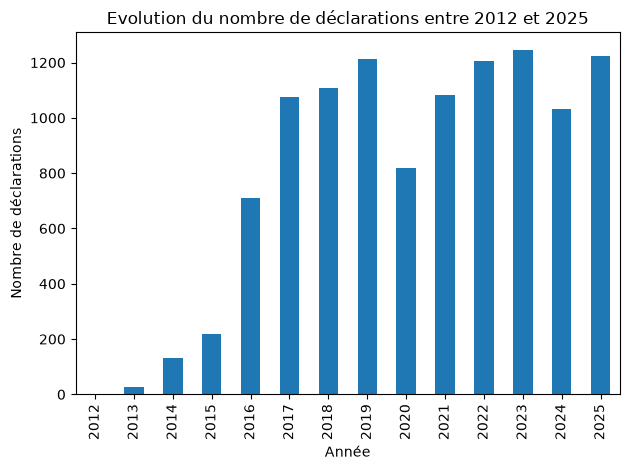

In [8]:
# EVOLUTION DU NOMBRE DE SIGNALEMENTS PAR AN
axe = data['ANNEEDECL'].value_counts().sort_index().plot.bar()
axe.set_xlabel("Année")
axe.set_ylabel("Nombre de déclarations")
axe.set_title("Evolution du nombre de déclarations entre 2012 et 2025")
plt.tight_layout()
plt.savefig("Outputs/Evolution_nombre_declarations_année.png", dpi=150)
plt.show()


L'augmentation du nombre entre 2013 et 2017 est vraisemblablement dûe à une popularisation de la plateforme. On voit également l'effet de la pandémie dans ces données : entre 2019 et 2020, les signalements de rats ont largement diminué puis dès 2021, le nombre de signalements à retrouvé ses valeurs habituelles. 
On peut prendre un autre angle d'analyse afin d'étudier les périodes où les rats sont davantage de sortie au cours d'une même année. Pour cela, on regarde le nombre total de signalements par mois (en accumulant les années) et on trace la moyenne pour avoir une idée de ce que cela représenterait sur une année représentative. 


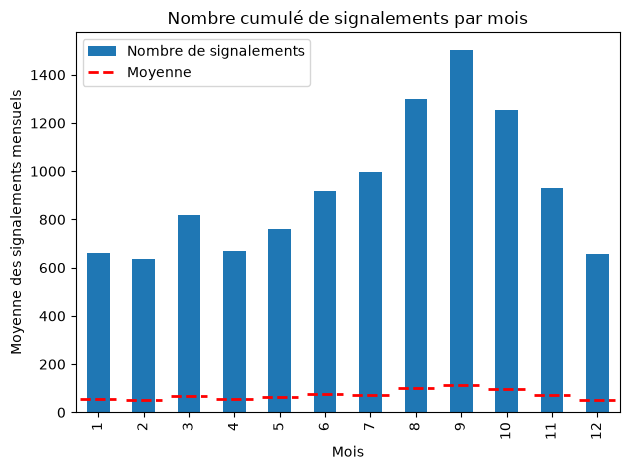

mois le plus infesté : 9, en moyenne 115.46153846153847 signalements.
mois le moins infesté : 12, en moyenne 50.46153846153846 signalements


In [9]:
# HISTOGRAMME D NOMBRE DE SIGNALEMENTS PAR MOIS, TOUTES ANNEES CONFONDUES
# calculons les moyennes mensuelles
comptages = data.groupby(['ANNEEDECL', 'MOISDECL']).size()
moyennes = comptages.groupby('MOISDECL').mean()
axe = data['MOISDECL'].value_counts(normalize=False).sort_index().plot.bar()
for i, moyenne in enumerate(moyennes):
    axe.hlines(
        y=moyenne,
        xmin=i-0.4,
        xmax=i+0.4,
        color='red',
        linestyle='--',
        linewidth=2,
        label='Moyenne mensuelle' if i == 0 else None
    )
axe.set_title('Nombre cumulé de signalements par mois')
axe.set_xlabel("Mois")
axe.set_ylabel("Moyenne des signalements mensuels")
handles, labels = axe.get_legend_handles_labels()
# pour pouvoir personnaliser la légende
axe.legend(
    handles=[handles[1], handles[0]],
    labels=['Nombre de signalements', 'Moyenne'],
    loc='best'
)
plt.tight_layout()
plt.savefig("Outputs/Signalements_par_mois.png", dpi=150)
plt.show()
print(f"mois le plus infesté : {moyennes.idxmax()}, en moyenne {moyennes.max()} signalements.")
print(f"mois le moins infesté : {moyennes.idxmin()}, en moyenne {moyennes.min()} signalements")


Lors du mois où les signalements sont les plus fréquents, en septembre, on a en moyenne 115.5 signalements chaque année. A contrario, en décembre (mois le moins infesté), il y a seulement 50.5 signalements en moyenne par an, soit 2,29 fois moins qu'en septembre. On voit ainsi une certaine dispersion des moyennes mensuelles. On peut faire l'hypothèse (ui sera testée par la suite), que le froid est moins propice à la sortie des rats, et que les rongeurs préfèrent la chaleur. 
Enfin, on peut croiser les deux graphiques précédents en s'intéressant à l'évolution du nombre de signalements par an en fonction des saisons. On peut comparer les fréquences à la tendance générale qui s'était dégagée dans le premier histogramme. 


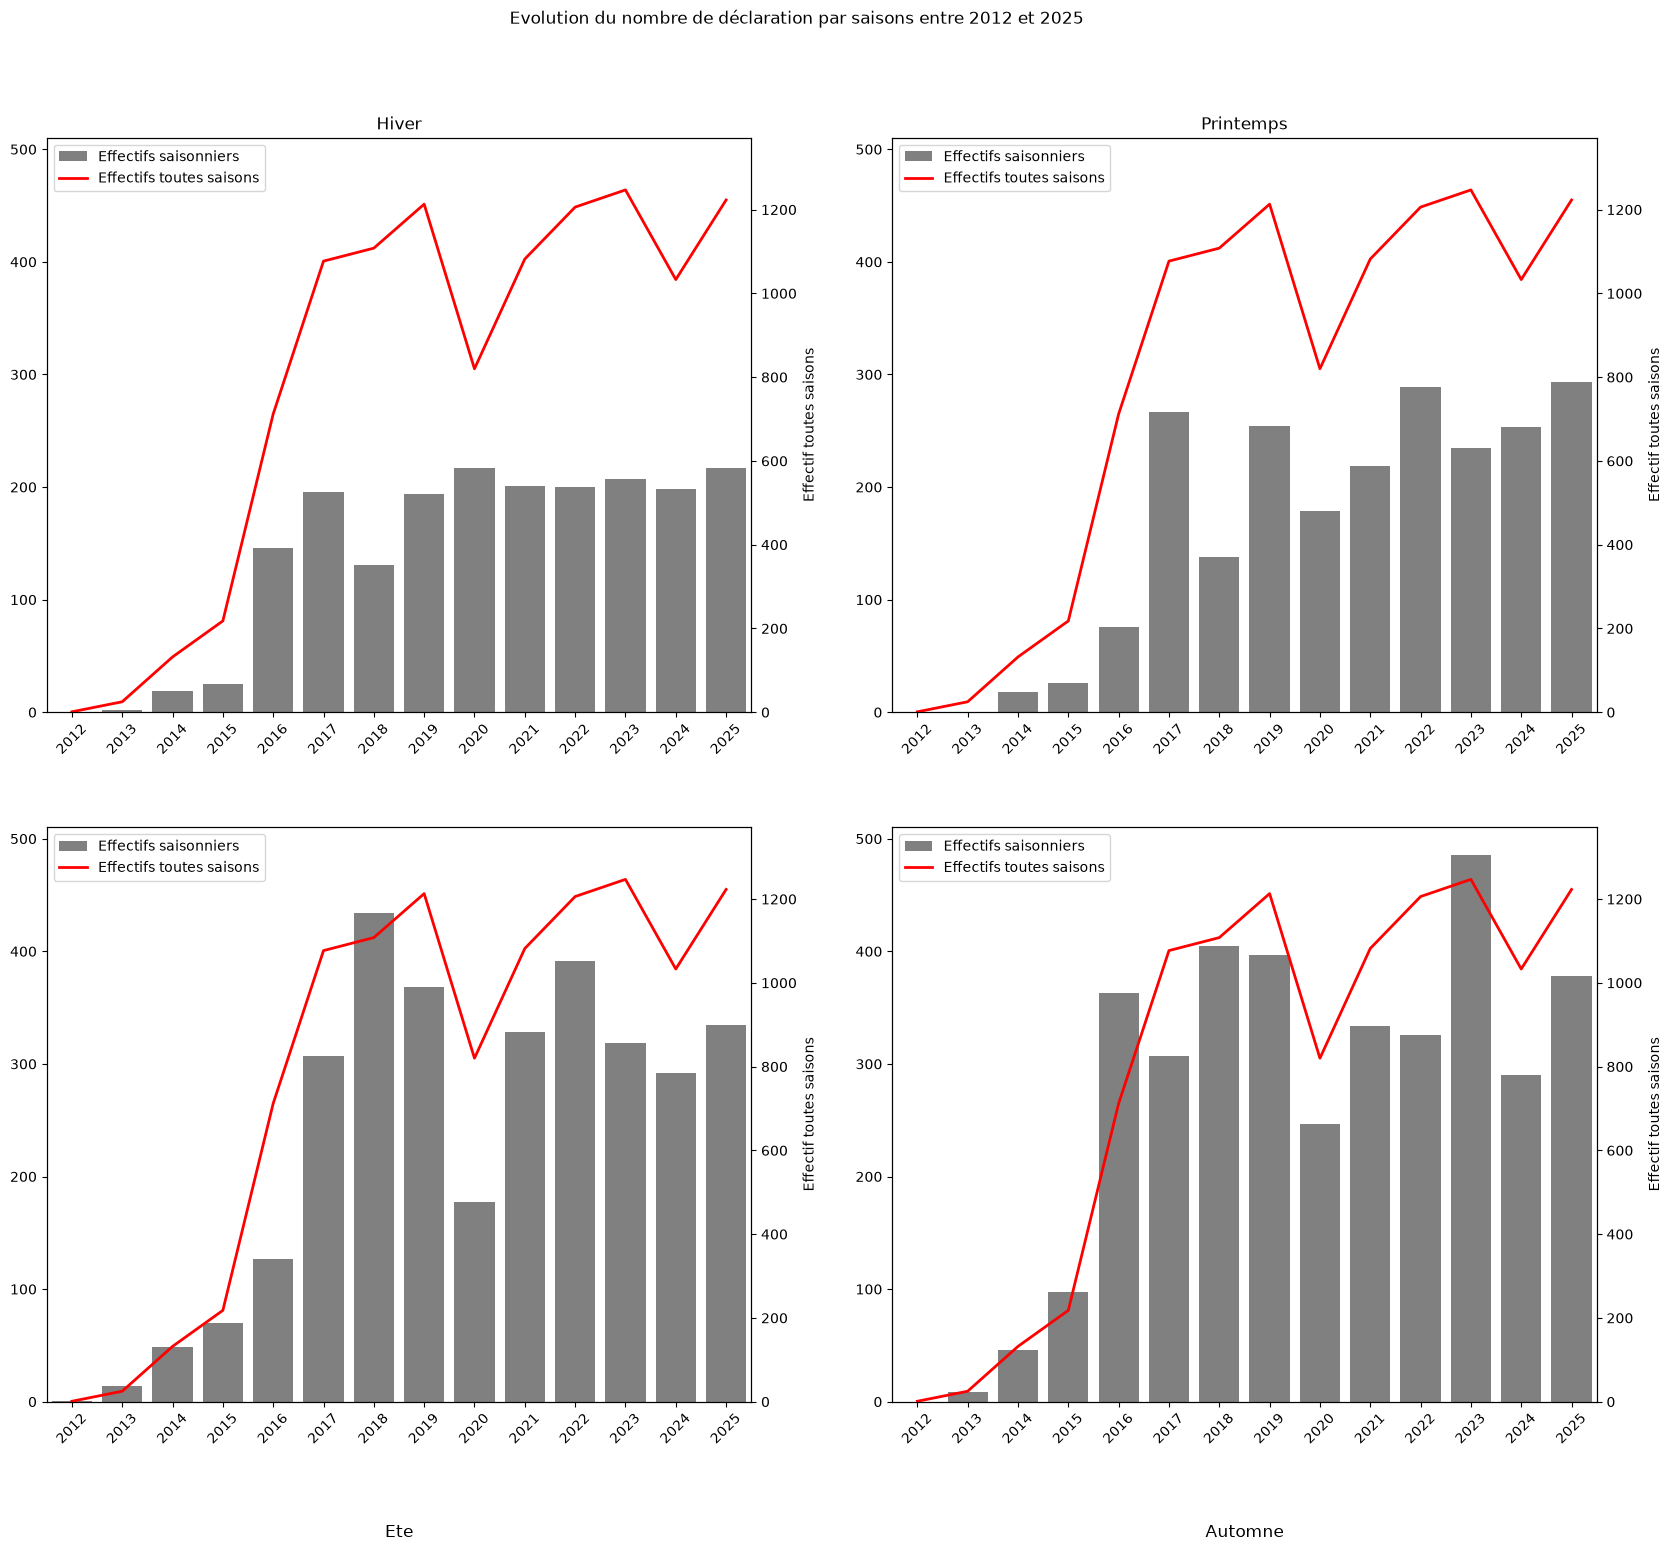

In [10]:
# HISTOGRAMME DE L'EVOLUTION DU NOMBRE DE SIGNALEMENTS SUR LA PERIODE PAR SAISON
# On rajoute la colonne saison au df
conditions = [data['MOISDECL'].isin([12, 1, 2]),
              data['MOISDECL'].isin([3, 4, 5]),
              data['MOISDECL'].isin([6, 7, 8]),
              data['MOISDECL'].isin([9, 10, 11])]
saisons = ["Hiver", "Printemps", "Ete", "Automne"]
data['SAISONDECL'] = np.select(conditions, saisons, default=None)

# pour comparer avec la tendance générale :
annees = sorted(data["ANNEEDECL"].dropna().unique())
tendance_annuelles = (
    data.groupby("ANNEEDECL")
    .size()
    .reindex(annees, fill_value=0)
)

# Les histogrammes
fig, axes1 = plt.subplots(2, 2, figsize=(20, 16))
plt.suptitle("Evolution du nombre de déclaration par saisons entre 2012 et 2025")
plt.subplots_adjust(top=0.90)
ymax_droite = tendance_annuelles.max()*1.1
positions = np.arange(len(tendance_annuelles))
annees = tendance_annuelles.index
for ax, saison in zip(axes1.flat, saisons):
    # 1er axe de gauche : effectifs par saison (les années manquantes à 0)
    effectifs_saison = (
        data.loc[data["SAISONDECL"] == saison, "ANNEEDECL"]
        .value_counts()
        .reindex(tendance_annuelles.index, fill_value=0)
        .sort_index()
    )
    ax.bar(positions, effectifs_saison.values, color='grey',
           label='Effectifs saisonniers')
    ax.set_title(saison)
    ax.set_xlabel("")
    ax.set_xticks(positions)
    ax.set_xticklabels(annees, rotation=45)
    # 2e axe, pour comparer avec la tendance par an
    axe2 = ax.twinx()
    axe2.plot(
        positions,
        tendance_annuelles.values,
        color='red', linestyle='-',
        linewidth=2, label='Effectifs toutes saisons'
    )
    axe2.set_ylim(0, ymax_droite)
    axe2.set_ylabel("Effectif toutes saisons")
    axe2.set_xlim(-0.5, len(tendance_annuelles)-0.5)

    # Légende :
    h1, l1 = ax.get_legend_handles_labels()
    h2, l2 = axe2.get_legend_handles_labels()
    ax.legend(h1+h2, l1+l2, loc="upper left")
# même échelle sur l'axe des ordonnées
ymax = max(ax.get_ylim()[1] for ax in axes1.flat)
for ax in axes1.flat:
    ax.set_ylim(0, ymax)
# Améliorer la lisibilité
axes1[1, 0].set_title("Ete", y=-0.25)
axes1[1, 1].set_title("Automne", y=-0.25)

plt.savefig("Outputs/Evolution du nombre de déclarations par saisons entre 2012 et 2025")
plt.show()


Tout d'abord on voit que c'est lors de l'été et de l'automne que les rongeurs sont davantage présents. D'ailleurs, si on voit une certaine régularité (et une petite croissance pour le printemps) dans les nombres de signalements lors des premiers semestres à partir de 2017, c'est que c'est visiblement le deuxième semestre qui est le plus variable, et qui porte majeure partie de la variabilité de la tendance de long terme. L'été et l'automne sont des saisons chaudes plus chaudes en générales, donc cela renforce l'hypothèse ci-dessus, que la chaleur pourrait expliquer en partie la présence de rats. 

A présent que nous avons décrit et extrait les informations importantes des données Dans Ma Rue, nous allons élargir le spectre des variables qui pourraient expliquer la présence signalée de rats.

# 2. Ajout de variables d'intérêt : la géographie parisienne
## 2.1 Récupération et nettoyage des donées

**Surfaces d'eau (IGN)**

Nos données sont issues de l'IGN. L'IGN (Institut Géographique National) est l'organisation publique de référence qui produit des données géographiques sur le territoire français. On utilise ici sa couche `surface_hydrographique`, qui contient les surfaces couvertes d'eau. Chaque surface a une nature (attribut `nature`) : écoulement naturel (la Seine, la Marne), canal (par exemple le canal Saint-Martin), retenue (les lacs des bois), etc.

Pour diffuser ses données, l'IGN passe par la Géoplateforme data.geopf.fr. On fait ses requêtes à la plateforme par un service WFS (Web Feature Service). Un WFS renvoie les objets eux-mêmes, avec leur géométrie et leurs attributs (alors qu'un service WMS renvoie une image de carte). Le rendu du WFS permet ainsi de calculer des distances.

La requête est une adresse web avec les  paramètres (`PARAMETRES_IGN` dans `eau.py`) :

- `REQUEST=GetFeature` (pour demander des objets)
- `TYPENAMES=BDTOPO_V3:surface_hydrographique` (la couche de la BD TOPO à interroger)
- `BBOX=2.20,48.80,2.50,48.92,CRS:84` (on ne prend ici que les objets d'un rectangle légèrement plus grand que Paris. Pour la localisation, on utilise les longitudes et latitudes du système WGS 84)
- `OUTPUTFORMAT=application/json` (indique d'un souhaite une réponse au format GeoJSON, facilement lisible)
- `COUNT=5000` (nombre maximal d'objets renvoyés).

Détails de `eau.py`

1. On envoie la requête via `telecharger_cours_d_eau`. Pour s'assurer de la qualité des données, la réponse indique le nombre d'objets correspondant à la demande (`numberMatched`). Si ce nombre dépasse le nombre d'objets reçus, c'est que l'IGN a coupé la réponse. La fonction s'arrête alors avec une erreur, plutôt que de continuer avec des données incomplètes.
2. On ne garde que deux natures (`NATURES_GARDEES`) : les écoulements naturels et les canaux. 
3. On enregistre le résultats dans `données/cours_d_eau.geojson`. La fonction `charger_cours_d_eau` lit cette copie si elle existe, sinon elle télécharge.
4. Les surfaces sont réunies en une seule forme sans l'altitude (en effet, la couche topographique de l'IGN est en 3D), puis converties en mètres sur un plan local pour pouvoir calculer des distances.

Le tableau ci-dessous compte les surfaces gardées, par nature.

In [11]:
eau = charger_cours_d_eau()
surfaces_eau = json.loads(FICHIER_EAU.read_text(encoding="utf-8"))["features"]

print(f"Natures gardées : {', '.join(NATURES_GARDEES)}")
natures = pd.Series([surface["properties"]["nature"] for surface in surfaces_eau])
natures.value_counts().rename_axis("nature").rename("nb_surfaces").to_frame()

Natures gardées : Ecoulement naturel, Canal


,nb_surfaces
nature,
Ecoulement naturel,20
Canal,15


**Arrondissements et espaces verts**

On utilise les datasets de l'API de opendata.paris.fr (ils sont téléchargés à chaque exécution). Le contour de Paris est l'union des 20 arrondissements. Les espaces verts sans géométrie sont écartés.

In [12]:
# polygone de chaque arrondissement, indexé par son numéro
def charger_arrondissements() -> pd.Series:
    reponse = requests.get(URL_ARRONDISSEMENTS, timeout=60)
    reponse.raise_for_status()
    polygones = {
        int(arrondissement["properties"]["c_ar"]): shape(arrondissement["geometry"])
        for arrondissement in reponse.json()["features"]
    }
    return pd.Series(polygones).sort_index()


arrondissements = charger_arrondissements()
contour = shapely.union_all(arrondissements.to_numpy())
espaces = telecharger_espaces_verts()

print(f"{len(arrondissements)} arrondissements, {len(espaces)} espaces verts avec une géométrie")
types_espaces_verts = pd.Series([espace["properties"].get("type_ev") for espace in espaces])
types_espaces_verts.value_counts().rename_axis("type_ev").rename("nb_objets").to_frame()

20 arrondissements, 2534 espaces verts avec une géométrie


,nb_objets
type_ev,
Végétalisation d'espace public,1012
Promenades ouvertes,598
Murs végétalisés,347
Périphérique,263
"Ephémères, partagés, pédagogiques",142
Jardinets décoratifs,117
Cimetières,21
Etablissements sportifs,19
Jardins privatifs,13


En regroupant la végétalisation, les murs, les talus et les jardinets, on voit que 68,6 % des objets sont de petits éléments de verdure, pas des parcs.

In [15]:
# signalements nettoyés en partie 1.1 ; la suite n'en utilise que la date, l'arrondissement et la position
rats = charger_signalements(FICHIER_RATS)

## 2.2 Création de nouvelles variables d'intérêt

On prend les signalements à partir de 2016. En effet, nous avons vu que c'était autour de cette année que la plateforme Dans Ma Rue gagnait en popularité, ce qui nous assure d'avoir des données un peu plus représentatives. 

**La distance à l'eau**\
Pour chaque signalement, le fichier `eau.py` calcule la distance du signalement à la surface d'eau la plus proche. On convertit les coordonnées en mètres sur un plan local.

**Grille de carreaux de 200 mètres**\
Le fichier `grille.py` découpe Paris en carreaux de 200 m de côté, à partir d'un coin situé au sud-ouest de Paris. On garde tous les carreaux inclus ou ayant une partie dans Paris. Un carreau pouvant être à cheval sur plusieurs arrondissements, on compte les arrondissements qui couvrent plus de 1 % de sa surface. 0 signifie que le carreau touche Paris sur moins de 1 % de sa surface. On place chaque signalements dans son carreau correspondant.
Enfin, chaque carreau comporte les signalements qui ont été faits dans sa surface entre 2016 et 2025.

In [16]:
carreaux = creer_carreaux(contour)
rats_periode = rats[rats["DATEDECL"] >= DATE_DEBUT]
# dans les données, X = longitude et Y = latitude
carreau_du_signalement = rattacher_aux_carreaux(rats_periode.rename(columns={"Y": "lat", "X": "lon"}), carreaux)

print(f"{len(carreaux)} carreaux de {TAILLE_CARREAU_M} m touchent Paris")
print(f"{len(rats_periode)} signalements depuis le {DATE_DEBUT}, dont {carreau_du_signalement.isna().sum()} hors des carreaux")

2799 carreaux de 200 m touchent Paris
10310 signalements depuis le 2016-01-01, dont 0 hors des carreaux


In [17]:
SEUIL_PART_ARRONDISSEMENT = 0.01

rectangles = shapely.box(
    carreaux["lon_min"].to_numpy(),
    carreaux["lat_min"].to_numpy(),
    carreaux["lon_max"].to_numpy(),
    carreaux["lat_max"].to_numpy(),
)
# part de la surface de chaque carreau (ligne) dans chaque arrondissement (colonne)
parts_par_arrondissement = pd.DataFrame({
    numero: shapely.area(shapely.intersection(rectangles, polygone)) / shapely.area(rectangles)
    for numero, polygone in arrondissements.items()
})
nb_arrondissements = (parts_par_arrondissement > SEUIL_PART_ARRONDISSEMENT).sum(axis=1)
nb_arrondissements.value_counts().sort_index().rename_axis("nb_arrondissements").rename("nb_carreaux").to_frame().T

nb_arrondissements,0,1,2,3,4
nb_carreaux,25,2408,339,25,2


Les variables du modèle spatial (en partie 4) sont mesurées au centre de chaque carreau par `decrire_carreaux` (`modele_spatial.py`) : distance à l'eau, distance à l'espace vert le plus proche (union de tous les espaces verts, bois compris), centre dans un espace vert, centre dans un bois, part de la surface du carreau dans Paris. `compter_par_carreau` ajoute le nombre de signalements de chaque carreau depuis `DATE_DEBUT`. On crée d'ores et déjà ce qui nous sera utile, car certaines variables seront utilisées très prochainement.

In [22]:
espaces_verts = unir_en_metres(espaces)
bois = unir_en_metres([espace for espace in espaces if espace["properties"].get("type_ev") == TYPE_BOIS])
carreaux = compter_par_carreau(rats, decrire_carreaux(carreaux, contour, eau, espaces_verts, bois), DATE_DEBUT)

dans_espace_vert = carreaux["dans_espace_vert"] == 1
distance_espace_vert_m = carreaux["distance_espace_vert_100m"] * 100
print(f"Carreaux à moins de 50 % dans Paris : {(carreaux['part_dans_paris'] < 0.5).sum()}")
print(f"Centre dans un espace vert : {dans_espace_vert.sum()} carreaux, dont {carreaux['dans_bois'].sum()} dans un bois "
      f"et {(dans_espace_vert & (carreaux[CIBLE] == 0)).sum()} sans signalement")
print(f"Distance du centre à l'espace vert le plus proche : médiane {distance_espace_vert_m.median():.0f} m, "
      f"maximum {distance_espace_vert_m.max():.0f} m")

Carreaux à moins de 50 % dans Paris : 164
Centre dans un espace vert : 606 carreaux, dont 435 dans un bois et 469 sans signalement
Distance du centre à l'espace vert le plus proche : médiane 49 m, maximum 449 m


## 2.3 Statistiques descriptives enrichies

**Signalements selon la distance à l'eau**

60 signalements à 0 m, c'est-à-dire dans une surface d'eau


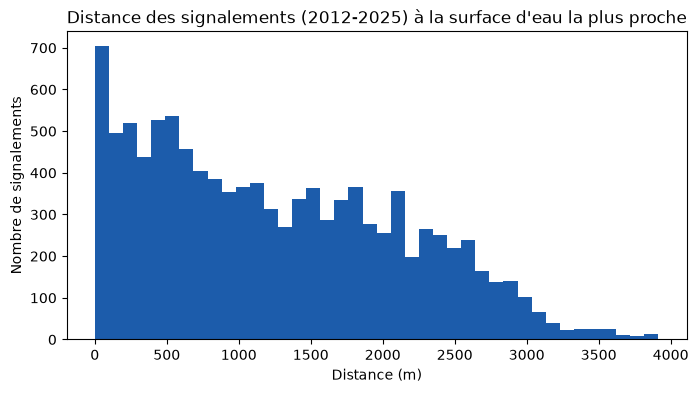

,count,mean,std,min,25%,50%,75%,max
distance_eau_m,1.067e+04,1249,881.5,0,486,1121,1920,3915


In [23]:

def tracer_histogramme(valeurs: pd.Series, titre: str, axe_x: str, axe_y: str, nb_classes: int = 40):
    figure, axe = plt.subplots(figsize=(8, 4))
    axe.hist(valeurs, bins=nb_classes, color=COULEUR)
    axe.set(title=titre, xlabel=axe_x, ylabel=axe_y)
    plt.show()


# distance de chaque signalement à l'eau (eau.py), sur les surfaces chargées en partie 2.1
distances_eau = ajouter_distance_eau(rats, eau)["distance_eau_m"]
print(f"{(distances_eau == 0).sum()} signalements à 0 m, c'est-à-dire dans une surface d'eau")
tracer_histogramme(
    distances_eau,
    "Distance des signalements (2012-2025) à la surface d'eau la plus proche",
    "Distance (m)",
    "Nombre de signalements",
)
distances_eau.describe().to_frame().T

La distance médiane d'un signalement à la Seine, à la Marne ou à un canal est de 1 125 m, et la plus grande de 3 915 m : aucun point de Paris n'est très loin de l'eau. L'histogramme décroît avec la distance, mais cela ne suffit pas à conclure que les signalements se concentrent près de l'eau : la Seine traverse la ville en son milieu.

60 signalements sont à 0 m, donc dans une surface d'eau. Il peut s'agir de points placés sur les quais ou les berges, inclus dans la surface d'eau de la BD TOPO, ou d'erreurs de localisation.

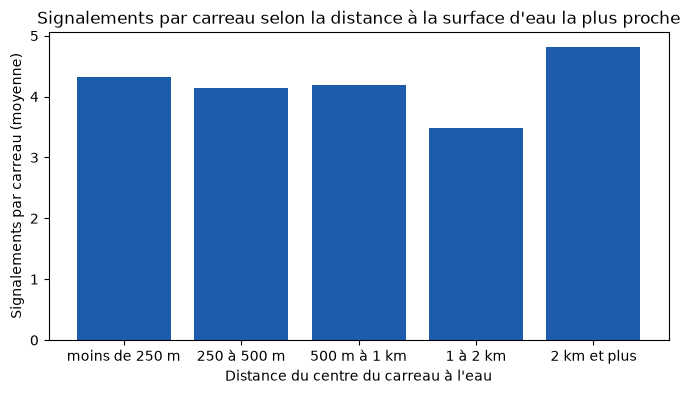

,nb_carreaux,moyenne
classe,,
moins de 250 m,323,4.322
250 à 500 m,267,4.142
500 m à 1 km,525,4.19
1 à 2 km,899,3.485
2 km et plus,475,4.819


In [24]:
SEUIL_CARREAU_INTERIEUR = 0.99

# nombre de carreaux et moyenne de signalements dans chaque classe
def moyenne_par_classe(carreaux: pd.DataFrame, classes: pd.Series) -> pd.DataFrame:
    return carreaux.groupby(classes, observed=True)[CIBLE].agg(nb_carreaux="size", moyenne="mean").rename_axis("classe")


# diagramme en barres des moyennes par classe
def tracer_moyennes(moyennes: pd.DataFrame, titre: str, axe_x: str):
    figure, axe = plt.subplots(figsize=(8, 4))
    axe.bar(moyennes.index.astype(str), moyennes["moyenne"], color=COULEUR)
    axe.set(title=titre, xlabel=axe_x, ylabel="Signalements par carreau (moyenne)")
    plt.show()


carreaux_interieurs = carreaux[carreaux["part_dans_paris"] > SEUIL_CARREAU_INTERIEUR]
classes_eau = pd.cut(
    carreaux_interieurs["distance_eau_km"] * 1000,
    bins=[0, 250, 500, 1000, 2000, np.inf],
    labels=["moins de 250 m", "250 à 500 m", "500 m à 1 km", "1 à 2 km", "2 km et plus"],
    right=False,
)
moyennes_eau = moyenne_par_classe(carreaux_interieurs, classes_eau)
tracer_moyennes(
    moyennes_eau,
    "Signalements par carreau selon la distance à la surface d'eau la plus proche",
    "Distance du centre du carreau à l'eau",
)
moyennes_eau

Avec la distance à l'eau, on ne ditingue pas de tendance nette : la moyenne reste entre 3,6 et 5,0 signalements par carreau quelle que soit la distance, avec un minimum entre 1 et 2 km (3,6) et un maximum au-delà de 2 km (5,0). La décroissance vue sur l'histogramme précédent venait donc sans doute de la géographie de Paris plutôt que d'un effet de l'eau : à surface égale, les carreaux proches de la Seine ou des canaux n'ont pas plus de signalements. On peut alors conjecturer que le coefficient de distance_eau_km sera non significatif dans la régression linéaire. A noter que les égouts, pourtant des endroits humides, ne sont pas pris en compte dans les surfaces d'eau considérées.

**Signalements par carreaux**

Total des signalements de chaque carreau depuis 2016. Sur la carte, les cases grises sont hors de Paris.


10310 signalements depuis le 2016-01-01, répartis sur 2799 carreaux
Carreaux sans signalement : 1171 (41.8%)


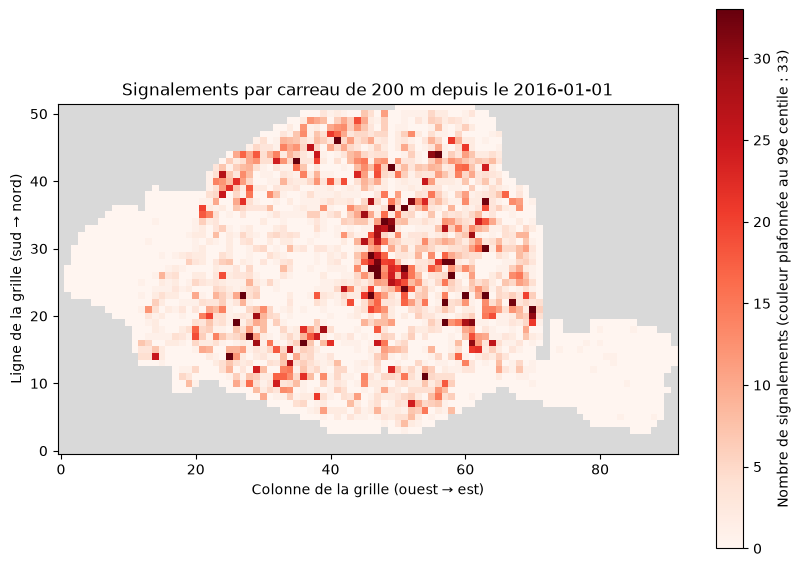

,count,mean,std,min,50%,75%,90%,99%,max
nb_signalements,2799,3.683,6.723,0,1,4,11,33,71


In [25]:
# carte de la grille : une case de l'image par carreau
def tracer_grille(carreaux: pd.DataFrame, colonne: str, titre: str, legende: str, maximum: float):
    image = carreaux.pivot(index="ligne", columns="colonne", values=colonne).reindex(
        index=range(carreaux["ligne"].max() + 1), columns=range(carreaux["colonne"].max() + 1)
    )
    palette = plt.get_cmap("Reds").copy()
    # cases sans carreau (hors de Paris)
    palette.set_bad("#d9d9d9")
    figure, axe = plt.subplots(figsize=(10, 7))
    # origin="lower" : la ligne 0 est en bas, donc le sud en bas
    rendu = axe.imshow(image, origin="lower", cmap=palette, vmin=0, vmax=maximum)
    figure.colorbar(rendu, ax=axe, label=legende)
    axe.set(title=titre, xlabel="Colonne de la grille (ouest → est)", ylabel="Ligne de la grille (sud → nord)")
    plt.show()


print(f"{carreaux[CIBLE].sum()} signalements depuis le {DATE_DEBUT}, répartis sur {len(carreaux)} carreaux")
print(f"Carreaux sans signalement : {(carreaux[CIBLE] == 0).sum()} ({(carreaux[CIBLE] == 0).mean():.1%})")
plafond = carreaux[CIBLE].quantile(0.99)
tracer_grille(
    carreaux,
    CIBLE,
    f"Signalements par carreau de {TAILLE_CARREAU_M} m depuis le {DATE_DEBUT}",
    f"Nombre de signalements (couleur plafonnée au 99e centile : {plafond:.0f})",
    plafond,
)
carreaux[CIBLE].describe(percentiles=[0.5, 0.75, 0.9, 0.99]).to_frame().T

On voit que les signalements sont très inégalement répartis : 41,8 % des carreaux n'en ont aucun en dix ans et la moitié en a au plus 1, alors que 1 % des carreaux en compte plus de 35 et le plus chargé 78. La moyenne (3,83) est bien au-dessus de la médiane (1), signe d'une distribution très asymétrique.

La carte montre une forte concentration au centre de Paris, autour des 1er à 4e arrondissements, et des carreaux chargés dispersés dans les arrondissements périphériques ; l'ouest (7e, 8e, 16e) est plus clair, et les bois de Boulogne et de Vincennes sont presque vides. Une partie de cette répartition peut venir de la fréquentation plutôt que de la présence réelle de rats : un signalement suppose qu'un passant voie un rat et le déclare.

## 2.4 Foyers de signalements (DBSCAN)

Sur le principe, DBSCAN permet de regrouper les points selon leur concentration. Cette méthode utilise deux paramètres : eps (rayon du voisinage d'un point, ici 100 mètres) et min_samples (le nombre minimal de points dans ce voisinage, le point central étant compris, ici 5). On accorde à chaque point un des trois statuts :
- point central : il a au moins min_samples points à moins de eps
- point de bordure : pas assez de voisins pour être voisin mais à moins de eps d'un point central
- bruit : ni l'un ni l'autre des statuts (étiquette -1)

`regrouper_points` (`DBSCAN.py`) applique l'algorithme DBSCAN aux coordonnées des signalements. La distance est la distance réelle sur la Terre : les coordonnées sont converties en radians, et le rayon de 100 m en angle, en le divisant par le rayon de la Terre (`RAYON_TERRE_M`). Le calcul se fait une année à la fois, avec les mêmes paramètres pour toutes les années, comme dans l'application.

In [26]:
# mêmes valeurs que dans app.py
EPS_FOYERS_M = 100
MIN_POINTS_FOYER = 5
ANNEES_FOYERS = range(2015, 2026)


# signalements d'une année en (lat, lon) ; dans les données, X = longitude et Y = latitude
def points_de_l_annee(rats: pd.DataFrame, annee: int) -> pd.DataFrame:
    selection = rats.loc[rats["DATEDECL"].dt.year == annee, ["Y", "X"]]
    return selection.rename(columns={"Y": "lat", "X": "lon"}).reset_index(drop=True)


# résumé des foyers trouvés par DBSCAN dans un ensemble de points
def resumer_foyers(points: pd.DataFrame, eps_metres: float, min_points: int) -> dict:
    groupes = pd.Series(regrouper_points(points, eps_metres, min_points))
    dans_un_foyer = groupes != -1
    tailles = groupes[dans_un_foyer].value_counts()
    # foyer d'un seul lieu : tous ses points ont exactement les mêmes coordonnées
    lieux_par_foyer = points.assign(groupe=groupes)[dans_un_foyer].drop_duplicates().groupby("groupe").size()
    return {
        "nb_signalements": len(points),
        "nb_foyers": len(tailles),
        "part_groupee": dans_un_foyer.mean(),
        "plus_gros_foyer": int(tailles.max()) if len(tailles) else 0,
        "part_plus_gros_foyer": tailles.max() / len(points) if len(tailles) else 0.0,
        "foyers_d_un_seul_lieu": int((lieux_par_foyer == 1).sum()),
    }


points_par_annee = {annee: points_de_l_annee(rats, annee) for annee in ANNEES_FOYERS}
pd.DataFrame([
    {"annee": annee, **resumer_foyers(points, EPS_FOYERS_M, MIN_POINTS_FOYER)}
    for annee, points in points_par_annee.items()
]).set_index("annee")

,nb_signalements,nb_foyers,part_groupee,plus_gros_foyer,part_plus_gros_foyer,foyers_d_un_seul_lieu
annee,,,,,,
2015,211,6,0.2085,9,0.04265,0
2016,631,29,0.3708,25,0.03962,5
2017,1029,46,0.4412,33,0.03207,1
2018,1059,39,0.4221,41,0.03872,2
2019,1177,51,0.4545,54,0.04588,2
2020,801,23,0.2634,33,0.0412,0
2021,1058,48,0.4121,24,0.02268,0
2022,1174,53,0.4497,28,0.02385,0
2023,1188,60,0.468,53,0.04461,0


Carte des foyers de la dernière année (2025):

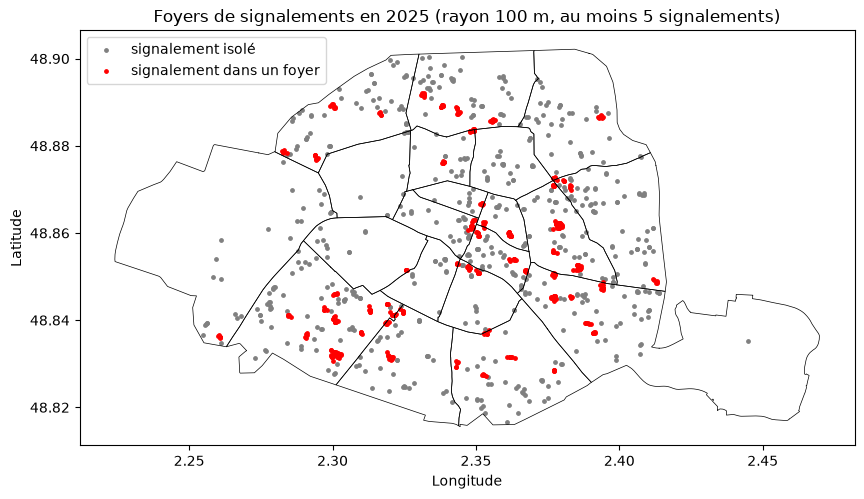

In [27]:
# signalements d'une année sur le fond des arrondissements : foyers en rouge, isolés en gris
def tracer_foyers(points: pd.DataFrame, eps_metres: float, min_points: int, arrondissements: pd.Series, titre: str):
    isoles = regrouper_points(points, eps_metres, min_points) == -1
    figure, axe = plt.subplots(figsize=(10, 7))
    for polygone in arrondissements:
        axe.plot(*polygone.exterior.xy, color="black", linewidth=0.5)
    axe.scatter(points.loc[isoles, "lon"], points.loc[isoles, "lat"], s=6, color="grey", label="signalement isolé")
    axe.scatter(points.loc[~isoles, "lon"], points.loc[~isoles, "lat"], s=6, color="red", label="signalement dans un foyer")
    # même longueur en mètres pour un degré affiché sur les deux axes, à la latitude de Paris
    axe.set_aspect(1 / COS_PARIS)
    axe.set(title=titre, xlabel="Longitude", ylabel="Latitude")
    axe.legend()
    plt.show()


derniere_annee = max(ANNEES_FOYERS)
tracer_foyers(
    points_par_annee[derniere_annee],
    EPS_FOYERS_M,
    MIN_POINTS_FOYER,
    arrondissements,
    f"Foyers de signalements en {derniere_annee} (rayon {EPS_FOYERS_M} m, au moins {MIN_POINTS_FOYER} signalements)",
)

Avec nos paramètres (voisinage 100m et 5 voisins), DBSCAN trouve chaque année (depuis 2016) entre 24 (en 2020) et 64 (en 2023) foyers, contre 6 en 2015. En dehors de la pandémie, 43 % à 52 % des signalements d'une année appartiennent à un foyer. Autrement dit, une grande partie des signalements n'est pas isolée, mais regroupée en petites zones. Les foyers restent petits : le plus gros réunit 67 signalements (2025), soit 5,5 % de ceux de l'année.

Sur la carte de 2025, les foyers sont répartis dans presque tous les arrondissements, avec davantage de foyers dans le 15e, l'est et le nord, et très peu dans l'ouest (7e, 8e, 16e) et dans les bois. Quelques foyers ne sont formés que de points aux mêmes coordonnées (7 en 2016) : ce sont plutôt des signalements répétés au même endroit que de vrais foyers.

Le choix de ces paramètres est discuté en annexe A, qui teste d'autres rayons et nombres minimaux de points.

## 2.5 Taux de signalement et niveau de vie par arrondissement

Pour comparer des arrondissements de tailles très différentes (le 15e est en effet le plus grand arrondissement de Paris), le nombre de signalements depuis 2016 est rapporté à la population : taux pour 10 000 habitants. Il est mis en parallèle avec niveau de vie médian de l'arrondissement.

- Population : populations légales de l'Insee, par l'API geo.api.gouv.fr.
- Niveau de vie : Insee, Filosofi 2023, niveau de vie médian (indicateur `MED_SL`, en euros par an et par unité de consommation) des arrondissements municipaux.

In [30]:
URL_COMMUNES = "https://geo.api.gouv.fr/communes"
# filosofi 2023, tous niveaux géographiques dont les arrondissements municipaux
URL_FILOSOFI = "https://www.insee.fr/fr/statistiques/fichier/8984752/FILOSOFI_CC_csv.zip"
FICHIER_FILOSOFI = "DS_FILOSOFI_CC_2023_data.csv"
POUR_HABITANTS = 10_000
# codes insee des arrondissements : 75101 à 75120
CODE_INSEE_PARIS = 75100


# population légale de chaque arrondissement, indexée par son numéro
def charger_population() -> pd.Series:
    parametres = {"type": "arrondissement-municipal", "codeDepartement": "75", "fields": "code,population"}
    reponse = requests.get(URL_COMMUNES, params=parametres, timeout=30)
    reponse.raise_for_status()
    communes = pd.DataFrame(reponse.json())
    if len(communes) != 20:
        raise ValueError(f"20 arrondissements attendus, {len(communes)} reçus")
    numeros = communes["code"].astype(int) - CODE_INSEE_PARIS
    return communes["population"].set_axis(numeros).rename_axis("arrondissement")


# niveau de vie médian de chaque arrondissement (indicateur MED_SL de filosofi)
def charger_niveau_de_vie() -> pd.Series:
    reponse = requests.get(URL_FILOSOFI, timeout=120)
    reponse.raise_for_status()
    # l'archive contient les données et un fichier de métadonnées
    with zipfile.ZipFile(io.BytesIO(reponse.content)) as archive:
        with archive.open(FICHIER_FILOSOFI) as fichier:
            filosofi = pd.read_csv(fichier, sep=";", dtype={"GEO": str})
    # ARM = arrondissement municipal ; 751xx = Paris
    paris = filosofi[
        (filosofi["GEO_OBJECT"] == "ARM")
        & filosofi["GEO"].str.startswith("751")
        & (filosofi["FILOSOFI_MEASURE"] == "MED_SL")
    ]
    if len(paris) != 20:
        raise ValueError(f"20 arrondissements attendus, {len(paris)} trouvés")
    numeros = paris["GEO"].astype(int) - CODE_INSEE_PARIS
    return paris["OBS_VALUE"].astype(int).set_axis(numeros).rename_axis("arrondissement")


# signalements, population, taux pour 10 000 habitants et niveau de vie, une ligne par arrondissement
def comparer_taux_et_niveau_de_vie(rats: pd.DataFrame, population: pd.Series, niveau_de_vie: pd.Series, debut: str) -> pd.DataFrame:
    signalements = rats.loc[rats["DATEDECL"] >= debut, "ARRONDISSEMENT"].value_counts()
    comparaison = pd.DataFrame({
        "population": population,
        "signalements": signalements,
        "niveau_vie_median": niveau_de_vie,
    })
    # un arrondissement absent d'une source laisserait une case vide
    if comparaison.isna().any().any():
        raise ValueError("arrondissement absent d'une des sources")
    comparaison["taux_10000_hab"] = comparaison["signalements"] / comparaison["population"] * POUR_HABITANTS
    return comparaison.sort_values("niveau_vie_median", ascending=False)


comparaison = comparer_taux_et_niveau_de_vie(rats, charger_population(), charger_niveau_de_vie(), DATE_DEBUT)
print(f"{comparaison['signalements'].sum()} signalements depuis le {DATE_DEBUT}, "
      f"{comparaison['population'].sum()} habitants")
comparaison

10310 signalements depuis le 2016-01-01, 2103778 habitants


,population,signalements,niveau_vie_median,taux_10000_hab
7,48015,135,52840,28.12
8,35317,162,51690,45.87
16,159386,418,49030,26.23
6,40389,149,48110,36.89
9,57271,252,43120,44
5,55252,328,40290,59.36
1,15114,481,39320,318.2
3,32179,178,38940,55.32
2,19847,174,38050,87.67
17,159212,942,37840,59.17


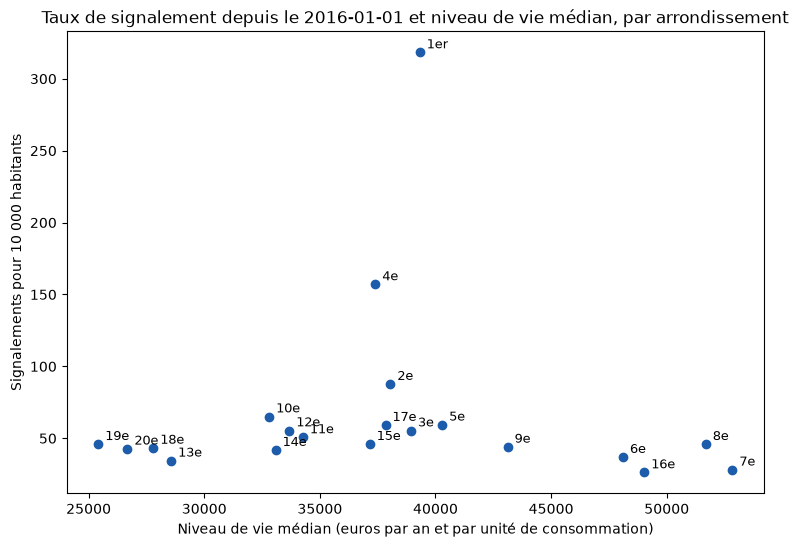

In [31]:
# nuage de points : un point par arrondissement, avec son numéro
def tracer_taux_et_niveau_de_vie(comparaison: pd.DataFrame, titre: str):
    figure, axe = plt.subplots(figsize=(9, 6))
    axe.scatter(comparaison["niveau_vie_median"], comparaison["taux_10000_hab"], color=COULEUR)
    for arrondissement, ligne in comparaison.iterrows():
        etiquette = "1er" if arrondissement == 1 else f"{arrondissement}e"
        axe.annotate(etiquette, (ligne["niveau_vie_median"], ligne["taux_10000_hab"]),
                     textcoords="offset points", xytext=(5, 3), fontsize=9)
    axe.set(
        title=titre,
        xlabel="Niveau de vie médian (euros par an et par unité de consommation)",
        ylabel="Signalements pour 10 000 habitants",
    )
    plt.show()


tracer_taux_et_niveau_de_vie(
    comparaison,
    f"Taux de signalement depuis le {DATE_DEBUT} et niveau de vie médian, par arrondissement",
)

Le taux de signalement ne suit pas le niveau de vie : les arrondissements les plus riches (7e, 8e, 16e) ont des taux faibles (27 à 48 signalements pour 10 000 habitants), mais les plus modestes (13e, 19e, 20e) aussi (35 à 48).

Les taux élevés sont ceux du centre : 1er (336), 4e (166) et 2e (94), des arrondissements peu peuplés mais très fréquentés. Rapporter les signalements aux seuls habitants y gonfle le taux, car beaucoup de signalements y sont sans doute faits par des personnes qui n'y habitent pas. Avec seulement 20 arrondissements, la comparaison reste fragile, et elle ne dit rien d'un lien éventuel à une échelle plus fine que l'arrondissement.

# 3. Etude de cas : lien avec les espaces verts et les composteurs

On cherche à déterminer s’il y a un lien entre les signalements de rats et les espaces verts de Paris. On utilise comme source la base de données “espaces verts et assimilés” de opendata.paris.fr, sous format geojson.

In [32]:
os.makedirs("Outputs", exist_ok=True)

# Paramètres 
BW = 10      # largeur des classes de distance (m)
RMAX = 450    # distance maximale affichée (m)
N_REF = 100_000  # nb de points aléatoires de référence
MIN_N = 20   #effectif minimal d'une classe pour calculer son ratio
RMAX_C = 2000     # composteurs : distance maximale
BW_C = 50   # composteurs : largeur des classes

# données
espaces_verts = gpd.read_file('données/espaces_verts.geojson')    # polygones (EPSG:4326)
data = pd.read_csv('données/clean_rats.csv')
points = gpd.GeoDataFrame(data, geometry=gpd.points_from_xy(data["X"], data["Y"]), crs="EPSG:4326")

# Contour de Paris et reprojection
paris_gdf = ox.geocode_to_gdf("Paris, France", which_result=1)
print(paris_gdf.geom_type.iloc[0], round(paris_gdf.to_crs(2154).area.iloc[0] / 1e6, 1), "km²")
paris = shapely.make_valid(paris_gdf.to_crs(2154).union_all())

ev = espaces_verts.to_crs(2154)
pts_all = points.to_crs(2154)

# Union des espaces verts, aussi hors Paris
ev_union = ev.union_all()

# Composteurs et arbre de recherche du plus proche voisin
composteurs = gpd.read_file('données/dechets-menagers-points-dapport-volontaire-composteurs.geojson').to_crs(2154)
arbre = cKDTree(composteurs.geometry.get_coordinates().to_numpy())

def tirer_dans(poly, n, rng):
    minx, miny, maxx, maxy = poly.bounds
    xs, ys = [], []
    while sum(len(a) for a in xs) < n:
        x = rng.uniform(minx, maxx, 2 * n)   # tirage dans le rectangle englobant
        y = rng.uniform(miny, maxy, 2 * n)
        m = shapely.contains_xy(poly, x, y)
        xs.append(x[m]); ys.append(y[m])     # on garde ceux qui tombent dans le polygone
    return np.concatenate(xs)[:n], np.concatenate(ys)[:n]

def ecdf(d, r): #fonction de répartition empirique
    d = np.sort(d)
    return np.searchsorted(d, r, side="right") / len(d)

def dist_au_plus_proche(x, y):
    d, _ = arbre.query(np.column_stack([x, y]))
    return d

Polygon 105.4 km²


In [34]:
def preparer(exclure_bois): #prepare la zone
    if exclure_bois:
        bois = ev[ev["type_ev"] == "Bois"].union_all()
        zone = shapely.make_valid(paris.difference(bois))
    else:
        bois = None
        zone = paris

    dans_paris = pts_all.intersects(paris).to_numpy()
    print(f"{len(pts_all)} observations au total, {(~dans_paris).sum()} hors du polygone de Paris")
    if exclure_bois:
        dans_bois = pts_all.intersects(bois).to_numpy() & dans_paris
        print(f"{dans_bois.sum()} observations dans les bois (retirées)")

    # On ne garde que les observations dans la zone d'étude
    pts = pts_all[pts_all.intersects(zone)].copy()
    print(f"{len(pts)} observations conservées dans la zone d'étude")

    # proportion d'observations dans les espaces verts
    dedans = pts.intersects(ev_union).to_numpy()
    n, k = len(pts), int(dedans.sum())
    p0 = zone.intersection(ev_union).area / zone.area   # part de la surface en espaces verts

    print("\n___ dans / hors espaces verts ___")
    print(f"Observations dans un espace vert : {k} / {n} = {k/n:.1%}")
    print(f"Part de la surface en espaces verts : {p0:.1%}")
    return zone, pts, dedans, n, k, p0

## 3.1 La question de l'inclusion des bois

On s’intéresse d’abord à la proportion des signalements dans les espaces verts, que l’on compare à la fraction de la surface de Paris occupée par des espaces verts.

In [35]:
print("######## EXCLURE_BOIS = False ########")
EXCLURE_BOIS = False
zone, pts, dedans, n, k, p0 = preparer(EXCLURE_BOIS)

######## EXCLURE_BOIS = False ########
11097 observations au total, 1 hors du polygone de Paris
11096 observations conservées dans la zone d'étude

___ dans / hors espaces verts ___
Observations dans un espace vert : 1968 / 11096 = 17.7%
Part de la surface en espaces verts : 23.4%


On pourrait en conclure que les rats ont tendance à éviter les espaces verts. Cependant, ces données sont biaisées par la présence du bois de Vincennes et du bois de Boulogne. En effet, ces deux espaces verts représentent une part importante de la surface de Paris, mais il n’y a que très peu de signalements de rats, ce qui peut s’expliquer par le fait que les gens fréquentent moins les bois que le reste de Paris et qu’ils ont moins tendance à y signaler les rats, puisqu’ils y causent moins de nuisances.

On fait le même test en excluant les deux bois, on obtient alors:

In [36]:
print("######## EXCLURE_BOIS = True ########")
EXCLURE_BOIS = True
rng = np.random.default_rng(0)    # graine réinitialisée : mêmes résultats que le script
zone, pts, dedans, n, k, p0 = preparer(EXCLURE_BOIS)

######## EXCLURE_BOIS = True ########
11097 observations au total, 1 hors du polygone de Paris
42 observations dans les bois (retirées)


11054 observations conservées dans la zone d'étude

___ dans / hors espaces verts ___
Observations dans un espace vert : 1926 / 11054 = 17.4%
Part de la surface en espaces verts : 8.3%


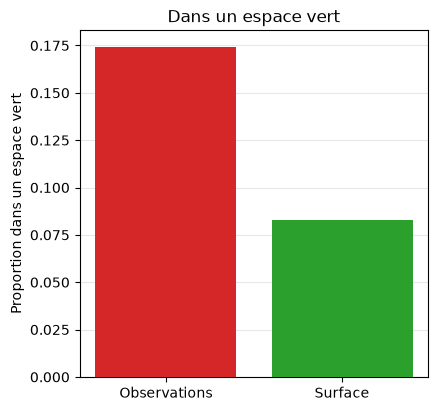

In [37]:
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.bar(["Observations", "Surface"], [k / n, p0], color=["tab:red", "tab:green"], zorder=3)
ax.set(ylabel="Proportion dans un espace vert", title="Dans un espace vert")
ax.grid(True, axis="y", alpha=0.3, zorder=0)
plt.savefig("Outputs/dans_espaces_verts.png", dpi=150, bbox_inches="tight")
plt.show()

Ceci confirme notre intuition, sur les 11096 observations dans Paris, seules 42 se situent dans un des bois de Paris, alors qu’ils représentent 15.1% de la surface de Paris. En les excluant, on trouve que les observations dans les espaces verts sont deux fois plus courantes que ce à quoi on s’attendrait avec des observations uniformément réparties.

On peut également étudier à quelle distance des espaces verts se situent les signalements qui ne sont pas situés dans un espace vert.


___hors espaces verts ___
9128 observations hors espaces verts
Quantiles 10/25/50/75/90/95 des observations : [  5.  11.  28.  72. 125. 159.]
Quantiles 10/25/50/75/90/95 de la référence  : [ 13.  33.  69. 119. 178. 221.]

Bande d'intensité relative maximale : 0-10 m
  ratio = 2.92 , 2063 observations dans la bande


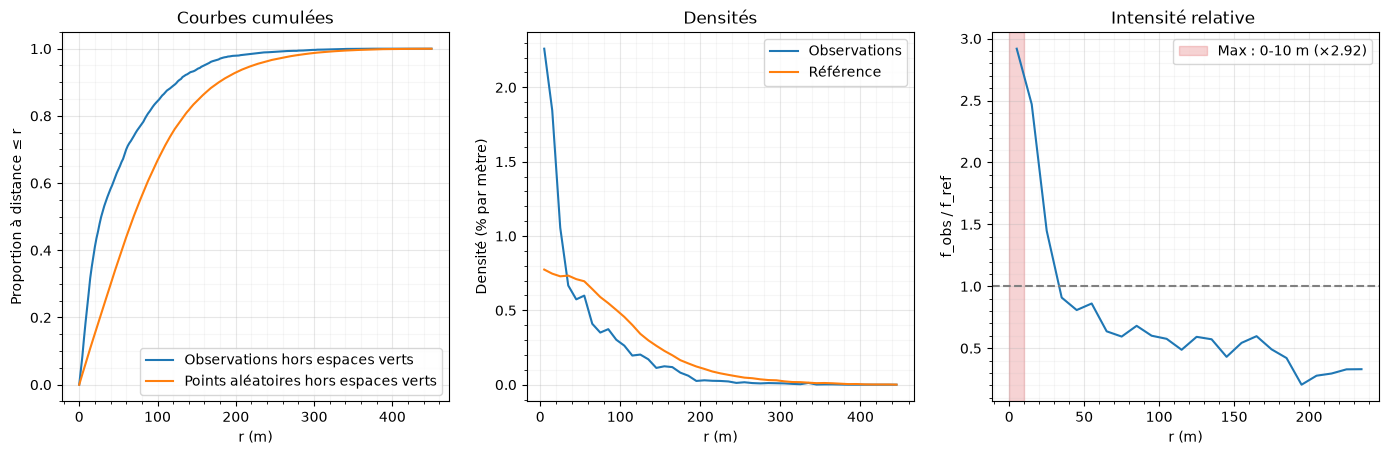

In [38]:
d_obs_out = pts.distance(ev_union).to_numpy()[~dedans]

# Référence : points uniformes dans la zone privée des espaces verts
zone_hors = shapely.make_valid(zone.difference(ev_union))
xo, yo = tirer_dans(zone_hors, N_REF, rng)
d_ref_out = shapely.distance(shapely.points(xo, yo), ev_union)

print("\n___hors espaces verts ___")
print(f"{len(d_obs_out)} observations hors espaces verts")
print("Quantiles 10/25/50/75/90/95 des observations :",
      np.percentile(d_obs_out, [10, 25, 50, 75, 90, 95]).round(0))
print("Quantiles 10/25/50/75/90/95 de la référence  :",
      np.percentile(d_ref_out, [10, 25, 50, 75, 90, 95]).round(0))

# Courbes cumulées conditionnelles
r = np.linspace(0, RMAX, RMAX // 2 + 1)
F_o, F_r = ecdf(d_obs_out, r), ecdf(d_ref_out, r)

# Densités conditionnelles
edges = np.arange(0, RMAX + BW, BW)
centres = (edges[:-1] + edges[1:]) / 2
h_o, _ = np.histogram(d_obs_out, bins=edges)
h_r, _ = np.histogram(d_ref_out, bins=edges)
f_o = h_o / len(d_obs_out) / BW
f_r = h_r / len(d_ref_out) / BW

# Ratio, là où les effectifs sont suffisants
valide = (h_o >= MIN_N) & (h_r > 0)
ratio = np.full(len(centres), np.nan)
ratio[valide] = f_o[valide] / f_r[valide]

i = int(np.nanargmax(ratio))   # bande d'intensité relative maximale
lo_b, hi_b = edges[i], edges[i + 1]
print(f"\nBande d'intensité relative maximale : {lo_b:.0f}-{hi_b:.0f} m")
print(f"  ratio = {ratio[i]:.2f} , {h_o[i]} observations dans la bande")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
ax[0].plot(r, F_o, label="Observations hors espaces verts")
ax[0].plot(r, F_r, label="Points aléatoires hors espaces verts")
ax[0].set(xlabel="r (m)", ylabel="Proportion à distance ≤ r", title="Courbes cumulées")
ax[0].legend()

ax[1].plot(centres, f_o * 100, label="Observations")
ax[1].plot(centres, f_r * 100, label="Référence")
ax[1].set(xlabel="r (m)", ylabel="Densité (% par mètre)", title="Densités")
ax[1].legend()

ax[2].plot(centres, ratio)
ax[2].axhline(1, color="grey", ls="--")
ax[2].axvspan(lo_b, hi_b, color="tab:red", alpha=0.2,
              label=f"Max : {lo_b:.0f}-{hi_b:.0f} m (×{ratio[i]:.2f})")
ax[2].set(xlabel="r (m)", ylabel="f_obs / f_ref", title="Intensité relative ")
ax[2].legend()

for a in ax:
    a.grid(True, alpha=0.3)
    a.minorticks_on()
    a.grid(True, which="minor", alpha=0.1)

plt.savefig("Outputs/hors_espaces_verts.png", dpi=150, bbox_inches="tight")
plt.show()

La surface est approximée par méthode de Monte-Carlo, avec 100 000 points pris aléatoirement dans le contour de Paris (ces points sont appelés “référence”). On constate que 10% des observations en dehors des espaces verts se situent à 5 mètres ou moins de l’espace vert le plus proche, alors que pour couvrir 10% de la surface de Paris (hors espaces verts), il faut considérer les 13 mètres qui entourent les espaces verts de Paris (bois compris). On constate également qu’un quart des signalements se situe à moins de 11 mètres d’un espace vert, alors que moins d’un dixième de la surface de Paris (hors espaces verts) se situe à moins de 11 mètres d’un espace vert.

“Courbes cumulées” représente en fonction d’une distance (notée r) la proportion de signalements hors d’un espace vert qui se situent au moins aussi proche d’un espace vert (en bleu), et la proportion de la surface de Paris (hors espaces verts, approximée par méthode de Monte-Carlo) qui se situe à une distance inférieure à r d’un espace vert. Ces deux courbes peuvent s’interpréter comme une fonction de répartition. On remarque une forme de domination stochastique au premier ordre.


“Densités” représente avec le même codage couleur la densité qui serait associé à la fonction de répartition représentée par le graphique “Courbes cumulées”, on y constate que les signalements (hors espaces verts) sont concentrés surtout au abords des espaces verts, et que cet effet chute rapidement lorsqu’on s’écarte des espaces verts. Cependant, on ne peut interpréter cette courbe sans la comparer à la manière dont évolue la surface considérée lorsque croît le rayon de recherche (ce qui est représenté par la courbe orange de ce graphe).


Ainsi, on trace le rapport de ces deux courbes dans le graphique “Intensité relative”, lorsque la courbe tracée est supérieure à 1, cela signifie que la proportion d’observations se situant à cette distance (à une précision de 10 mètres près) d’un espace vert est supérieure à proportion de la surface de Paris (hors espaces verts) à cette même distance d’un espace vert. On remarque que cette courbe est supérieure à 1 en dessous de 30 mètres de distance puis reste inférieure à 1 et varie peu. On en déduit que les signalements de rats sont plus fréquents près des espaces verts que ce à quoi on s’attendrait avec des observations uniformément réparties. De plus, cette surreprésentation est maximale sur la zone couvrant les 10 mètres les plus proches des espaces verts, on l’on trouve 2,92 fois plus de signalements que ce que l’on aurait pour des observations uniformément réparties dans Paris. À une distance comprise entre 10 et 20 mètres de tout espace vert, on constate 2,5 fois plus d’observations de rats que ce qu’on aurait pour des observations réparties uniformément. Entre 20 et 30 mètres, cette intensité relative chute à ≈ 1,45. Au delà de 40 mètres, les rats sont sous-représentés. Il semble que la courbe présente une tendance décroissante, cependant, comme d’après le premier graphique, il reste moins de 10% des observations de rats hors espaces verts à plus de 150 mètres de tout espace vert, ces données sont certainement moins robuste que celles de la bande 0-10 mètres, qui contient à elle seule 2063 observations.

Étant donnés l’importance de l’effet mesuré ainsi que la taille de notre échantillon, on peut en conclure avec un haut degré de certitude que les signalements de rats sont biens plus courants dans les espaces verts (bois de Paris exclus), ainsi qu’aux abords des espaces verts.

## 3.2 Composteurs : distance au composteur le plus proche

De la même manière que l’on a étudié la distance des signalements aux espaces verts de Paris en la comparant à ce qu’on obtiendrait pour des points uniformément répartis (la référence), on peut étudier la distance des observations aux composteurs de Paris.

On utilise pour cela la base de données “Déchets ménagers - Points d'apport volontaire - Composteurs” de opendata.paris.fr, format geojson, qui recense les 99 composteurs de Paris. On exclut à nouveau les bois de Paris de notre périmètre d’étude.



___ COMPOSTEURS ___
11054 observations
Quantiles 10/25/50/75/90/95 des observations : [ 134.  250.  428.  671. 1015. 1425.]
Quantiles 10/25/50/75/90/95 de la référence  : [ 174.  298.  509.  827. 1432. 1781.]

Bande d'intensité relative maximale : 0-50 m
  ratio = 3.36, 329 observations dans la bande


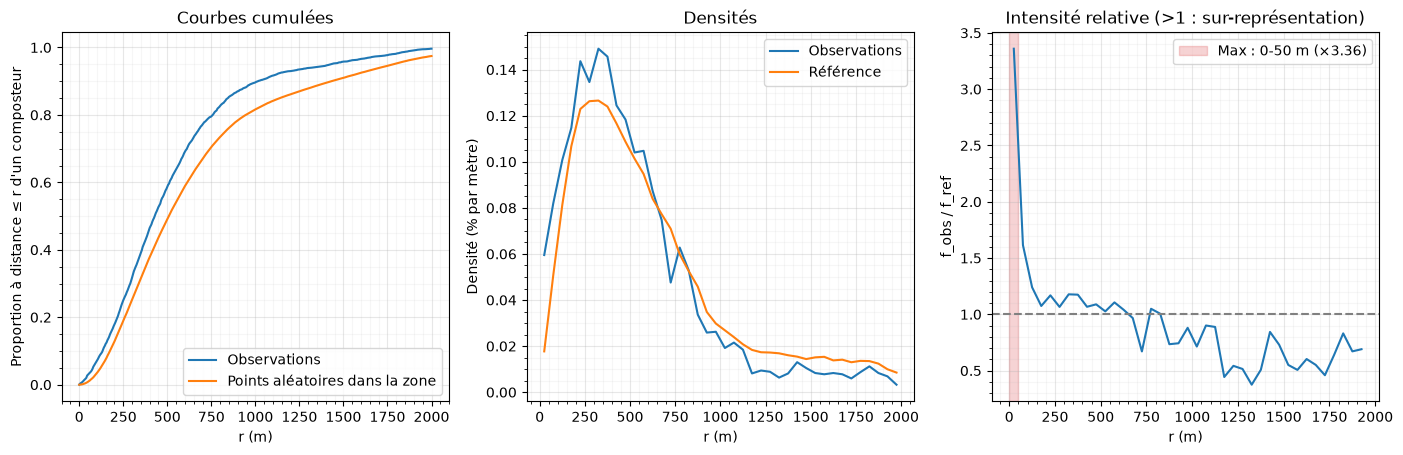

In [39]:
# Distances des observations
xy_obs = pts.geometry.get_coordinates().to_numpy()
d_obs_c = dist_au_plus_proche(xy_obs[:, 0], xy_obs[:, 1])

# Points de référence uniformes dans la zone d'étude
xc, yc = tirer_dans(zone, N_REF, rng)
d_ref_c = dist_au_plus_proche(xc, yc)

print("\n___ COMPOSTEURS ___")
print(f"{len(d_obs_c)} observations")
print("Quantiles 10/25/50/75/90/95 des observations :",
      np.percentile(d_obs_c, [10, 25, 50, 75, 90, 95]).round(0))
print("Quantiles 10/25/50/75/90/95 de la référence  :",
      np.percentile(d_ref_c, [10, 25, 50, 75, 90, 95]).round(0))

# Courbes cumulées
r_c = np.linspace(0, RMAX_C, RMAX_C // 5 + 1)
F_o_c, F_r_c = ecdf(d_obs_c, r_c), ecdf(d_ref_c, r_c)

# Densités
edges_c = np.arange(0, RMAX_C + BW_C, BW_C)
centres_c = (edges_c[:-1] + edges_c[1:]) / 2
h_o_c, _ = np.histogram(d_obs_c, bins=edges_c)
h_r_c, _ = np.histogram(d_ref_c, bins=edges_c)
f_o_c = h_o_c / len(d_obs_c) / BW_C
f_r_c = h_r_c / len(d_ref_c) / BW_C

# Ratio
valide_c = (h_o_c >= MIN_N) & (h_r_c > 0)
ratio_c = np.full(len(centres_c), np.nan)
ratio_c[valide_c] = f_o_c[valide_c] / f_r_c[valide_c]

i_c = int(np.nanargmax(ratio_c))
lo_c, hi_c = edges_c[i_c], edges_c[i_c + 1]
print(f"\nBande d'intensité relative maximale : {lo_c:.0f}-{hi_c:.0f} m")
print(f"  ratio = {ratio_c[i_c]:.2f}, {h_o_c[i_c]} observations dans la bande")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
ax[0].plot(r_c, F_o_c, label="Observations")
ax[0].plot(r_c, F_r_c, label="Points aléatoires dans la zone")
ax[0].set(xlabel="r (m)", ylabel="Proportion à distance ≤ r d'un composteur", title="Courbes cumulées")
ax[0].legend()

ax[1].plot(centres_c, f_o_c * 100, label="Observations")
ax[1].plot(centres_c, f_r_c * 100, label="Référence")
ax[1].set(xlabel="r (m)", ylabel="Densité (% par mètre)", title="Densités")
ax[1].legend()

ax[2].plot(centres_c, ratio_c)
ax[2].axhline(1, color="grey", ls="--")
ax[2].axvspan(lo_c, hi_c, color="tab:red", alpha=0.2,
              label=f"Max : {lo_c:.0f}-{hi_c:.0f} m (×{ratio_c[i_c]:.2f})")
ax[2].set(xlabel="r (m)", ylabel="f_obs / f_ref", title="Intensité relative (>1 : sur-représentation)")
ax[2].legend()

for a in ax:
    a.grid(True, alpha=0.3)
    a.minorticks_on()
    a.grid(True, which="minor", alpha=0.1)

plt.savefig("Outputs/composteurs.png", dpi=150, bbox_inches="tight")
plt.show()

# Distances aux espaces verts, et appartenance à un espace vert (pour les deux études suivantes)
d_ev_obs = pts.distance(ev_union).to_numpy()
d_ev_ref = shapely.distance(shapely.points(xc, yc), ev_union)
dedans_obs = pts.intersects(ev_union).to_numpy()
pts_ref = shapely.points(xc, yc)
dedans_ref = shapely.intersects(pts_ref, ev_union)

Là encore, il apparaît que les signalements sont proches des composteurs: les 10% d’observations les plus proches de composteurs sont à moins de 134 mètres alors que parmi nos points pris de manière indépendante et uniforme dans Paris, les 10% les plus proches sont au plus  à 174 mètres.


On reconnaît sur le graphique “Courbes cumulées” la dominance stochastique du premier ordre qu’on avait également dans l’analyse de la distance aux espaces verts, ceci signifie que les signalements sont en moyenne plus proches des composteurs que ce que le hasard pur laisserait supposer. Sur le graphe “Densités”, on remarque qu’hormis en dessous de 250 mètres de distance et au dessus de 1250 mètres, la courbe des observations empiriques suit à peu près la courbe des points uniformes. Ce rapport est quantifié par le graphique “Intensité relative”. Comme précédemment, on constate que les signalements sont particulièrement surreprésentés près des composteurs, en effet, sur la zone à une distance de 0 à 50 mètres de tout composteur, on a 329 observations, ce qui est 3,36 fois plus que ce qu’on obtient avec nos points uniforméments répartis. Ici aussi, cette surreprésentation chute très rapidement, et devient quasiment nulle dès 250 mètres de distance, au-delà de 1000 mètres de distance, les signalements sont sous-représentés. Cependant, les effectifs pour chaque zone sont plus faibles que dans l’étude des espaces verts, ainsi, on ne peut statuer sur le niveau exact de l’effet de  la distance au composteur le plus proche.


### Étude 1 : composteurs, observations dans les espaces verts

Les deux effets établis précédemment  sont liés, en effet, les composteurs sont souvent placés proches d’espaces verts. On va ici essayer d’étudier les deux effets simultanément. D’une part, on considère les observations dans les espaces verts (bois exclus, comme toujours), et on trace les mêmes graphiques que précédemment en fonction de la distance au composteur le plus proche. On constate que même dans les espaces verts, la distance à un composteur est déterminante. Cependant, nous avons seulement 1926 observations dans les espaces verts, ces résultats sont donc moins robustes que ceux concernant les signalements hors espaces verts.

Dans espaces verts : 1926 obs., 8315 points de référence


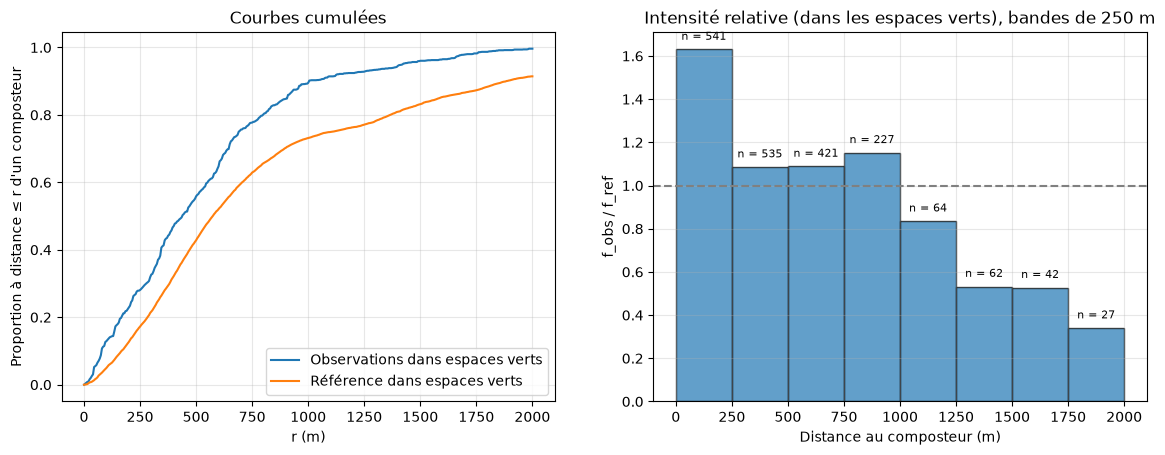

In [40]:
d_in_o = d_obs_c[dedans_obs]
d_in_r = d_ref_c[dedans_ref]
print(f"Dans espaces verts : {dedans_obs.sum()} obs., {dedans_ref.sum()} points de référence")

# Panneau gauche : courbes cumulées
r_in = np.linspace(0, RMAX_C, RMAX_C // 5 + 1)

# Panneau droit : bandes de 250 m
BW_IN = 250
edges_in = np.arange(0, RMAX_C + BW_IN, BW_IN)
h_o, _ = np.histogram(d_in_o, bins=edges_in)
h_r, _ = np.histogram(d_in_r, bins=edges_in)
ratio_in = np.full(len(h_o), np.nan)
v = (h_o >= MIN_N) & (h_r > 0)
ratio_in[v] = (h_o[v] / len(d_in_o)) / (h_r[v] / len(d_in_r))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
ax[0].plot(r_in, ecdf(d_in_o, r_in), label="Observations dans espaces verts")
ax[0].plot(r_in, ecdf(d_in_r, r_in), label="Référence dans espaces verts")
ax[0].set(xlabel="r (m)", ylabel="Proportion à distance ≤ r d'un composteur", title="Courbes cumulées")
ax[0].legend()

ax[1].bar(edges_in[:-1], np.nan_to_num(ratio_in), width=BW_IN, align="edge", edgecolor="k", alpha=0.7)
ax[1].axhline(1, color="grey", ls="--")
ymax = np.nanmax(ratio_in) if np.isfinite(ratio_in).any() else 1
for x0, n_b, rt in zip(edges_in[:-1], h_o, ratio_in):
    y = rt if np.isfinite(rt) else 0
    ax[1].text(x0 + BW_IN / 2, y + 0.02 * ymax, f"n = {n_b}", ha="center", va="bottom", fontsize=8)
ax[1].set_xticks(edges_in)
ax[1].set(xlabel="Distance au composteur (m)", ylabel="f_obs / f_ref",
          title="Intensité relative (dans les espaces verts), bandes de 250 m")

for a in ax:
    a.grid(True, alpha=0.3)
plt.savefig("Outputs/composteurs_dans_ev.png", dpi=150, bbox_inches="tight")
plt.show()

### Étude 2 : composteurs × espaces verts, observations hors espaces verts

Pour tester s’il existe une relation monotone entre la distance aux espaces verts et aux composteurs pour les points de référence hors espaces verts, on calcule la corrélation de Spearman (c’est le coefficient de corrélation entre les rangs de ces deux variables pour les points de référence), on obtient 0,17. Cela signifie qu’il y a une légère relation croissante entre ces deux variables pour des points uniformément répartis dans Paris hors espaces verts.


Hors espaces verts : 9128 obs., 91685 points de référence
Spearman (référence hors espaces verts) : 0.17


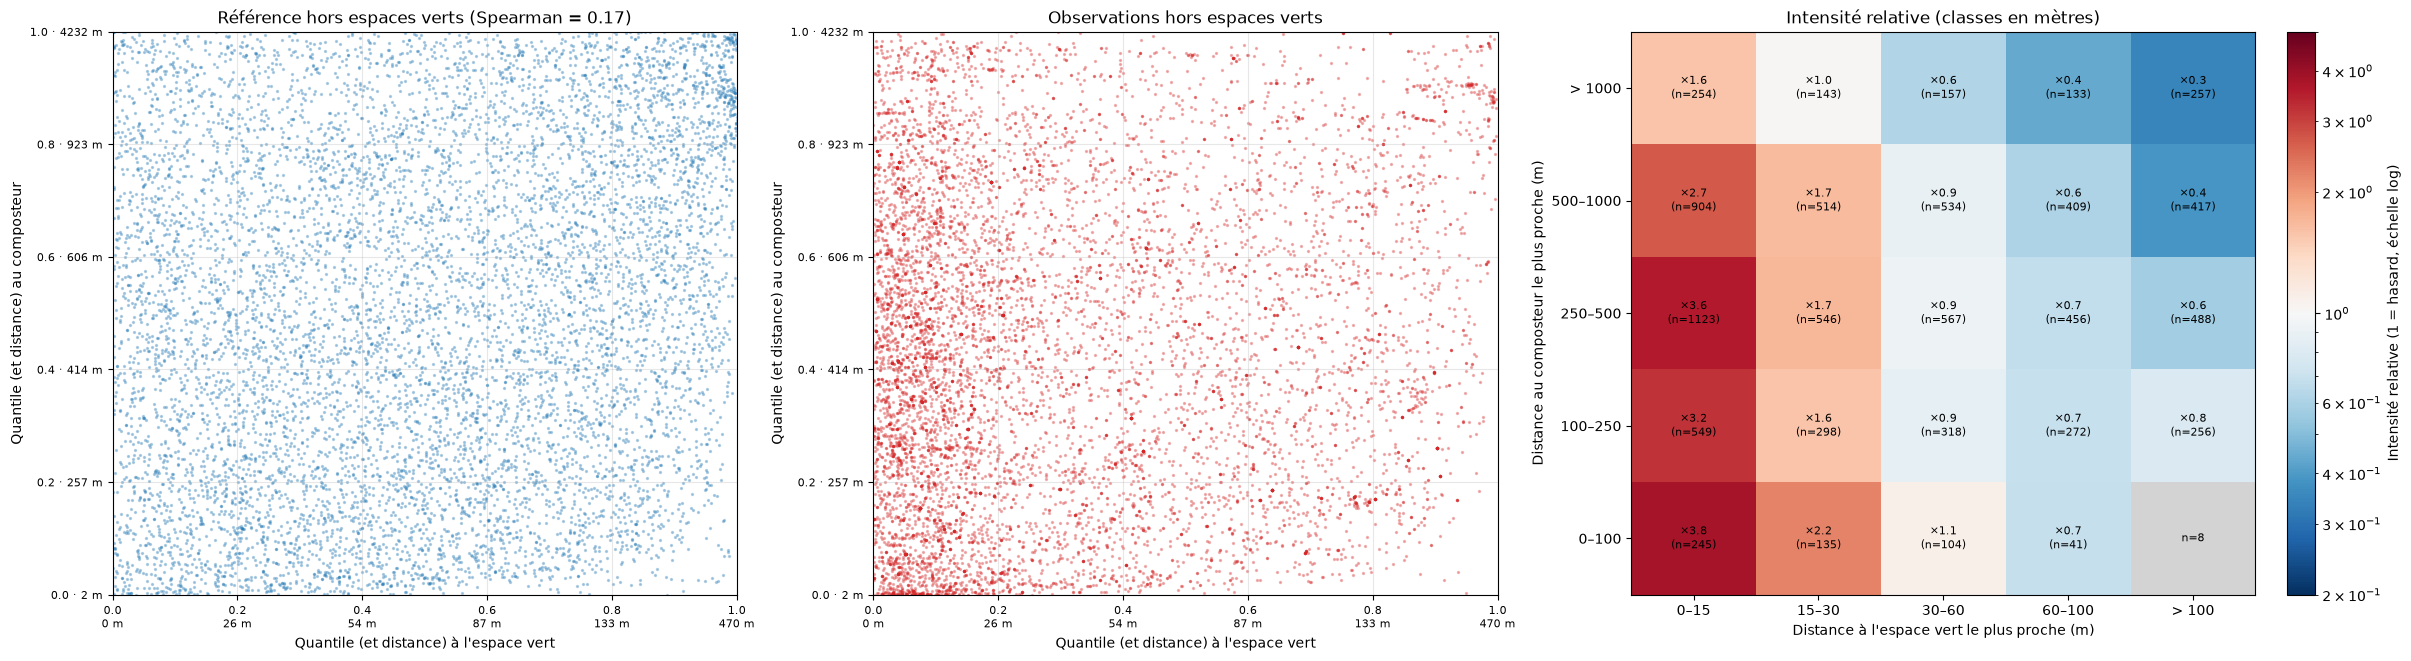

In [41]:
dev_o = d_ev_obs[~dedans_obs]; dc_o = d_obs_c[~dedans_obs]
dev_r = d_ev_ref[~dedans_ref]; dc_r = d_ref_c[~dedans_ref]
print(f"Hors espaces verts : {len(dev_o)} obs., {len(dev_r)} points de référence")

rho_out = stats.spearmanr(dev_r, dc_r)[0]
print("Spearman (référence hors espaces verts) :", rho_out.round(2))

# Quantiles de la RÉFÉRENCE appliqués aux deux jeux (panneaux gauche et centre)
u_r, u_o = ecdf(dev_r, dev_r), ecdf(dev_r, dev_o)
v_r, v_o = ecdf(dc_r, dc_r), ecdf(dc_r, dc_o)

def graduations2(ax, dx, dy, pas=0.2, fontsize=8):
    q = np.round(np.arange(0, 1 + 1e-9, pas), 2)
    ax.set_xticks(q); ax.set_xticklabels([f"{x:.1f}\n{np.quantile(dx, x):.0f} m" for x in q], fontsize=fontsize)
    ax.set_yticks(q); ax.set_yticklabels([f"{x:.1f} · {np.quantile(dy, x):.0f} m" for x in q], fontsize=fontsize)

# Classes en mètres pour la carte d'intensité relative (panneau de droite)
bins_ev = [0, 15, 30, 60, 100, np.inf]
bins_c  = [0, 100, 250, 500, 1000, np.inf]

def etiquettes(bins):
    return [f"{int(a)}–{int(b)}" if np.isfinite(b) else f"> {int(a)}"
            for a, b in zip(bins[:-1], bins[1:])]

H_o, _, _ = np.histogram2d(dev_o, dc_o, bins=[bins_ev, bins_c])
H_r, _, _ = np.histogram2d(dev_r, dc_r, bins=[bins_ev, bins_c])
R = (H_o / H_o.sum()) / np.where(H_r > 0, H_r / H_r.sum(), np.nan)
R_aff = np.where(H_o >= MIN_N, R, np.nan)   # faible effectif : case grisée

fig, ax = plt.subplots(1, 3, figsize=(24, 6.5), constrained_layout=True)

# Panneau de gauche : référence
sel = np.random.default_rng(1).choice(len(u_r), size=min(len(u_o), len(u_r)), replace=False)
ax[0].scatter(u_r[sel], v_r[sel], s=2, alpha=0.3)
ax[0].set_title(f"Référence hors espaces verts (Spearman = {rho_out:.2f})")

# Panneau central : signalements
ax[1].scatter(u_o, v_o, s=2, alpha=0.3, color="tab:red")
ax[1].set_title("Observations hors espaces verts")

for a in ax[:2]:
    a.set(xlabel="Quantile (et distance) à l'espace vert", ylabel="Quantile (et distance) au composteur",
          xlim=(0, 1), ylim=(0, 1))
    graduations2(a, dev_r, dc_r)
    a.grid(True, alpha=0.3)

# Panneau de droite : intensité relative, classes en mètres
cmap = plt.get_cmap("RdBu_r").copy(); cmap.set_bad("lightgrey")
m = ax[2].pcolormesh(np.arange(len(bins_ev)), np.arange(len(bins_c)), R_aff.T,
                     cmap=cmap, norm=LogNorm(vmin=0.2, vmax=5), shading="flat")
plt.colorbar(m, ax=ax[2], label="Intensité relative (1 = hasard, échelle log)")

for i in range(R.shape[0]):
    for j in range(R.shape[1]):
        txt = (f"×{R[i, j]:.1f}\n(n={int(H_o[i, j])})" if H_o[i, j] >= MIN_N
               else f"n={int(H_o[i, j])}")
        ax[2].text(i + 0.5, j + 0.5, txt, ha="center", va="center", fontsize=8)

ax[2].set_xticks(np.arange(len(bins_ev) - 1) + 0.5); ax[2].set_xticklabels(etiquettes(bins_ev))
ax[2].set_yticks(np.arange(len(bins_c) - 1) + 0.5);  ax[2].set_yticklabels(etiquettes(bins_c))
ax[2].set(xlabel="Distance à l'espace vert le plus proche (m)",
          ylabel="Distance au composteur le plus proche (m)",
          title="Intensité relative (classes en mètres)")

plt.savefig("Outputs/rangs_2d_hors_ev.png", dpi=150, bbox_inches="tight")
plt.show()

Sur le graphique précédent sont représentés à gauche: les points de référence, dont les coordonnées ne sont pas leur distance en mètres aux espaces verts et aux composteurs, mais les quantiles correspondant à ces distances. S’il y avait une relation monotone parfaite entre la distance aux espaces verts et la distance aux composteurs, tous ces points seraient alignés.
Sur le graphique du centre, on représente les signalements de rats avec la même échelle que le graphique précédent (c’est-à-dire que sur les axes, les quantiles spécifiés sont ceux calculés avec la distribution des points de référence). On constate que ces points ne sont pas répartis comme ceux du premier graphique, ce qui indique que leur distribution est différente. En effet, on remarque qu’ils sont plus concentrés à gauche.

Pour quantifier cette différence, on procède comme précédemment en calculant l’intensité relative, c’est-à-dire la proportion de signalements obtenus divisée par la proportion à laquelle on s’attendrait avec des signalements uniformément répartis sur la surface de Paris.
On remarque que le coin inférieur gauche est celui où la surreprésentation est la plus forte (245 signalements 3,8 fois plus qu’avec des observations uniformément réparties), le coin supérieur droit est celui avec la plus forte sous représentation (257 observations, 0,3 fois ce qu’on aurait avec des observations uniformément réparties). Dans la zone a plus de 100 mètres de l’espace vert le plus proche et à moins de 100 mètres du composteur le plus proche, on a seulement 8 signalements, donc on ne peut statuer raisonnablement sur l’intensité relative. On constate également que la proximité à l’espace vert le plus proche est le facteur qui semble le  plus important, et que cet effet semble renforcé quand le composteur le plus proche est à moins de 500 mètres. Toute la partie supérieure droite est en bleu, cela signifie que les rats sont particulièrement sous-représentés lorsque les espaces verts et les composteurs sont loins.

# 4. Analyse : deux modèles linéaires

Cette partie estime deux modèles à partir des signalements nettoyés en partie 1.1 (`données/clean_rats.csv`) et de la météo (`données/clean_meteo.csv`) :

1. un modèle temporel : nombre de signalements par arrondissement et par jour, selon la météo et la saison (`prediction.py`) ;
2. un modèle spatial : nombre total de signalements par carreau de 200 m, selon la distance à l'eau et aux espaces verts (`modele_spatial.py`).

Le code des modèles est dans ces deux fichiers ; ce notebook appelle leurs fonctions. Les signalements sont chargés en partie 2.1 ; les carreaux et leurs variables viennent de la partie 2.2.

Types de signalement. Les trois sous-types gardés en partie 1.1 (« Présence de rats », « Présence de souris », « Rats sortant des égouts ») ne sont pas distingués : chaque ligne compte pour un signalement, et la colonne `SOUSTYPE` n'est pas utilisée. Ces sous-types décrivent presque la même chose, un rongeur vu par un passant, et le choix entre eux dépend de la personne qui signale (partie 1.2). Sur les 10 721 signalements depuis 2016, 10 137 (94,5 %) sont des « Présence de rats », 546 des « Présence de souris » et 38 des « Rats sortant des égouts ».

p-valeur : seuil minimal à partir duquel on rejette l'hypothèse nulle.

In [30]:
# taille de l'échantillon et qualité d'ajustement, sur une ligne
def resumer_modele(resultat) -> pd.DataFrame:
    return pd.DataFrame([{
        "observations": int(resultat.nobs),
        "R2": resultat.rsquared,
        "R2_ajuste": resultat.rsquared_adj,
    }])


# test de Wald, H0 : tous les coefficients de la liste sont nuls
def test_joint(resultat, variables: list) -> pd.DataFrame:
    test = resultat.f_test(", ".join(f"{variable} = 0" for variable in variables))
    # selon les cas, statsmodels renvoie un nombre ou un tableau à un élément
    return pd.DataFrame([{
        "nb_contraintes": len(variables),
        "F": np.asarray(test.fvalue).item(),
        "p_valeur": np.asarray(test.pvalue).item(),
    }])

## 4.1 Signalements par arrondissement et par jour

### Construction

Dans `clean_rats.csv`, une ligne correspond à un signalement. Pour expliquer un nombre de signalements, on les compte par jour et par arrondissement. Toutes les combinaisons jour × arrondissement sont gardées, y compris celles sans aucun signalement (valeur 0).

- Cible : `nb_signalements`, nombre de signalements dans l'arrondissement ce jour-là. Les signalements identiques à un autre (même lieu, même date) sont tous comptés.
- Météo (`clean_meteo.csv`, une valeur par jour pour tout Paris) : température maximale du jour, et `pluie_veille`, qui vaut 1 si la veille a reçu au moins 1 mm de pluie. Le premier jour de la météo est retiré, car sa veille n'est pas connue.
- Saison et arrondissement : indicatrices, avec le printemps et le 1er arrondissement comme références.
- Estimation : moindres carrés ordinaires, écarts-types robustes à l'hétéroscédasticité (HC1).

Les distances à l'eau et aux espaces verts ne sont pas dans ce modèle : elles ne sont mesurées qu'à l'emplacement des signalements, donc elles n'existent pas pour les arrondissements-jours sans signalement. Elles sont utilisées dans le modèle spatial (4.2).

La population de l'arrondissement n'est pas ajoutée au modèle, pour les raisons données en annexe C.1.

### Période d'estimation

Le modèle part de la date `DATE_DEBUT` de `prediction.py`. Le choix repose sur le nombre de signalements par année (graphique de la partie 1.3).

In [31]:
meteo = charger_meteo(FICHIER_METEO)
panel = filtrer_periode(construire_panel(rats, meteo), DATE_DEBUT)

print(f"Début de la période : {DATE_DEBUT}")
print(f"Seuil de pluie : {SEUIL_PLUIE_MM} mm")
print(f"Références : saison {SAISON_REFERENCE}, arrondissement {ARRONDISSEMENT_REFERENCE}")
print(f"{len(panel)} observations : {panel['DATE'].nunique()} jours x {panel['ARRONDISSEMENT'].nunique()} arrondissements, "
      f"du {panel['DATE'].min():%Y-%m-%d} au {panel['DATE'].max():%Y-%m-%d}")

Début de la période : 2016-01-01
Seuil de pluie : 1.0 mm
Références : saison Printemps, arrondissement 1
73060 observations : 3653 jours x 20 arrondissements, du 2016-01-01 au 2025-12-31


### Distribution de la cible

In [32]:
pd.DataFrame([{
    "moyenne": panel[CIBLE].mean(),
    "part_de_zeros": (panel[CIBLE] == 0).mean(),
    "part_a_1": (panel[CIBLE] == 1).mean(),
    "maximum": panel[CIBLE].max(),
}])

,moyenne,part_de_zeros,part_a_1,maximum
0,0.1467,0.8827,0.09647,24


La cible est presque toujours nulle : 88,3 % des arrondissements-jours n'ont aucun signalement, 9,6 % en ont exactement un, et seulement 2,1 % en ont deux ou plus. La moyenne est de 0,147 signalement par arrondissement et par jour. Le maximum, 24 signalements, est atteint dans le 9e le 20 septembre 2016 ; ces 24 signalements ne portent que sur 8 lieux distincts, et sans les lignes identiques, aucun arrondissement-jour ne dépasse 8 signalements.

Une telle cible convient mal à un modèle linéaire : celui-ci prédit une moyenne, qui peut être négative (les prédictions négatives sont ramenées à 0 dans les prévisions), et la variance des résidus n'est pas constante, d'où les écarts-types robustes (HC1) (cf cours d'écono). Les coefficients se lisent donc comme des écarts de nombre moyen de signalements, et non comme des probabilités. Le modèle linéaire a l'avantage de coefficients directement lisibles en nombre de signalements.

### Estimation sur toute la période

In [33]:
resultat_temporel = estimer_modele(panel)

resumer_modele(resultat_temporel)

,observations,R2,R2_ajuste
0,73060,0.03587,0.03556


In [34]:
tableau_coefficients(resultat_temporel)

,beta,ecart_type,p_valeur
const,0.05503,0.01012,5.435e-08
MAX_TEMPERATURE_C,0.003778,0.0003647,3.873e-25
pluie_veille,-0.008621,0.00355,0.01517
saison_Ete,0.01116,0.005876,0.05756
saison_Automne,0.06876,0.005098,1.811e-41
saison_Hiver,0.01368,0.004853,0.00483
arr_2,-0.08815,0.009137,5.045e-22
arr_3,-0.08924,0.008788,3.14e-24
arr_4,-0.01478,0.01055,0.1613
arr_5,-0.04818,0.009417,3.119e-07


Tests joints de Wald : pour chaque groupe de variables, H0 = tous les coefficients du groupe sont nuls.

In [35]:
tests_joints(resultat_temporel)

,groupe,nb_contraintes,F,p_valeur
0,global (toutes sauf constante),24,119.2,0
1,meteo,2,61.2,2.782e-27
2,saisons,3,64.73,8.641e-42
3,arrondissements,19,141.2,0


On traite ici la période de début 2016 à fin 2025, soit 73 060 arrondissements-jours. Chaque coefficient se lit en nombre de signalements par arrondissement et par jour, toutes choses égales par ailleurs. Pour comparaison, la moyenne est de 0,147 signalement par arrondissement et par jour, soit environ 2,9 pour tout Paris.

Température. Un degré de plus de température maximale est associé à 0,0038 signalement de plus par arrondissement et par jour (p ≈ 4e-25, significatif à tous les seuils usuels). L'effet d'un degré est minime, mais il s'additionne : entre une journée à 5 °C et une journée à 25 °C, l'écart est de 0,076 signalement par arrondissement, soit environ la moitié de la moyenne, ou 1,5 signalement de plus par jour pour tout Paris. Cela rejoint la partie 1.3, où septembre compte 2,3 fois plus de signalements que décembre.

Pluie de la veille. Contrairement à l'idée que la pluie ferait sortir les rats, une veille pluvieuse (au moins 1 mm) est associée à 0,0086 signalement de moins par arrondissement et par jour (p = 1,5 %) : le coefficient est significatif aux seuils de 10 % et 5 %, mais pas à 1 %. L'écart est faible, environ 6 % de la moyenne. Le modèle ne dit pas pourquoi : moins de rats dehors, ou moins de passants pour les voir et les signaler. Les deux sont indiscernables ici, puisque les données mesurent des signalements et non des rats.

Saisons. Les coefficients des saisons se lisent par rapport au printemps, à température et pluie égales. Comme la chaleur est déjà prise en compte par la température, ils mesurent ce que la saison ajoute à la température. L'automne se détache : 0,069 signalement de plus par arrondissement et par jour (p ≈ 2e-41), autant que 18 °C de plus. L'hiver est aussi au-dessus du printemps (0,014 de plus, p = 0,5 %, significatif à 1 %), et l'été légèrement (0,011 de plus, p = 5,8 %, significatif à 10 % seulement). Le test joint rejette nettement l'hypothèse que les trois coefficients soient nuls (F = 64,7, p ≈ 9e-42).

Ces p-valeurs supposent que les 20 arrondissements d'un même jour sont indépendants, alors qu'ils partagent la même météo.

Arrondissements. Les coefficients se lisent par rapport au 1er arrondissement. La météo et la saison étant les mêmes pour tous les arrondissements un jour donné, ils mesurent simplement l'écart de moyenne journalière avec le 1er. Le 15e a le coefficient le plus élevé : 0,16 signalement de plus par jour que le 1er (p ≈ 5e-34, la plus petite p-valeur du modèle), devant le 17e (0,13). Le 7e a le plus faible : 0,10 signalement de moins par jour que le 1er (p ≈ 8e-31), presque à égalité avec le 6e (0,098 de moins). Entre le 15e et le 7e, l'écart est de 0,26 signalement par jour, soit environ 95 par an. Seuls le 4e et le 10e ne se distinguent pas du 1er au seuil de 5 % (p = 16 % et 18 %).

Le R² est de 3,6 % : le modèle explique très peu des variations d'un arrondissement-jour à l'autre. Ce n'est pas surprenant, puisque 88 % des arrondissements-jours n'ont aucun signalement et que le jour précis d'un signalement dépend de circonstances (un passant, un rat visible à ce moment) qu'aucune de ces variables ne capte. Le modèle décrit des niveaux moyens ; il prévoit mal un jour donné.

### Prévision hors échantillon

Le modèle est réestimé sur les jours avant `DATE_DEBUT_TEST`, puis évalué sur les jours suivants, qu'il n'a pas vus. Les prédictions négatives sont ramenées à 0. Il est comparé à une référence qui prédit simplement, pour chaque arrondissement, sa moyenne de signalements par jour sur la période d'apprentissage.

In [36]:
test = filtrer_periode(panel, DATE_DEBUT_TEST)
print(f"Apprentissage : {DATE_DEBUT} -> {DATE_DEBUT_TEST} exclu ; test : {DATE_DEBUT_TEST} -> {test['DATE'].max():%Y-%m-%d}")
print(f"Part de zéros sur la période de test : {(test[CIBLE] == 0).mean():.1%}")

evaluer_prevision(panel, DATE_DEBUT_TEST)

Apprentissage : 2016-01-01 -> 2024-01-01 exclu ; test : 2024-01-01 -> 2025-12-31
Part de zéros sur la période de test : 87.3%


,prediction,R2_test,RMSE_test,MAE_test
0,modele,0.03298,0.4399,0.252
1,reference (moyenne par arrondissement),0.02995,0.4406,0.2529


Sur 2024-2025, que le modèle n'a pas vus, il obtient un R² de test de 0,033, proche du R² obtenu sur l'ensemble de la période (0,036) : les liens estimés sur 2016-2023 restent valables en 2024-2025. Mais il fait à peine mieux que la référence, qui prédit pour chaque arrondissement sa moyenne journalière de 2016-2023 : R² de test 0,033 contre 0,030, erreur quadratique moyenne (RMSE) 0,4399 contre 0,4406, erreur absolue moyenne (MAE) 0,2520 contre 0,2529. Une fois l'arrondissement connu, la météo et la saison n'ajoutent donc presque rien à la prévision : l'essentiel de ce que le modèle prévoit tient aux différences moyennes entre arrondissements.

Les erreurs restent grandes par rapport à la cible : une erreur absolue moyenne de 0,25 signalement, pour une moyenne de 0,15. Elles viennent des 87,3 % de zéros de la période de test : le modèle prédit chaque jour une petite valeur positive, alors que la réalité est presque toujours 0, parfois 1 ou plus.

Un exemple de prédiction, celle que calcule l'application, est donné en annexe B.

## 4.2 Signalements par carreau de 200 m

### Construction

Paris est découpé en carreaux de 200 m (`grille.py`). Tous les carreaux qui touchent Paris sont gardés, y compris ceux sans signalement.

- Cible : `nb_signalements`, total des signalements du carreau depuis `DATE_DEBUT` (même période que le modèle 4.1).
- Variables, mesurées au centre du carreau :
  - `distance_eau_km` : distance à la surface d'eau la plus proche (Seine, Marne, canaux ; BD TOPO de l'IGN, `eau.py`) ;
  - `distance_espace_vert_100m` : distance à l'espace vert le plus proche (jeu `espaces_verts` de l'open data de Paris, bois compris), en centaines de mètres ;
  - `dans_espace_vert` : 1 si le centre est dans un espace vert ;
  - `dans_bois` : 1 si le centre est dans un des deux bois (les bois étant aussi des espaces verts, cette indicatrice mesure l'écart entre les bois et les autres espaces verts) ;
  - `part_dans_paris` : part de la surface du carreau dans Paris (les carreaux de bordure sont en partie hors de Paris).
- Estimation : moindres carrés ordinaires, écarts-types HC1 (c'est le cours d'écono, il ne faut pas demander :) ).

L'indicatrice des composteurs et la population des carreaux ont été écartées : voir l'annexe C.2.

In [39]:
carreaux[[CIBLE, *VARIABLES_SPATIALES]].describe()

,nb_signalements,distance_eau_km,distance_espace_vert_100m,part_dans_paris,dans_espace_vert,dans_bois
count,2799,2799,2799,2799,2799,2799
mean,3.83,1.241,0.6666,0.9405,0.2165,0.1554
std,7.071,0.8716,0.6996,0.2008,0.4119,0.3624
min,0,0,0,2.717e-09,0,0
25%,0,0.5224,0.05565,1,0,0
50%,1,1.136,0.4898,1,0,0
75%,4,1.828,1.023,1,0,0
max,78,4.193,4.488,1,1,1



Avant d'interpréter les coefficients, il faut souligner l'hétérogénéité de la répartition des signalements. Sur les 2 799 carreaux de 200 m × 200 m, 41,8 % n'ont aucun signalement depuis 2016. La médiane est de 1 signalement par carreau, pour une moyenne de 3,83 : quelques carreaux très chargés (78 signalements pour le plus chargé) tirent la moyenne vers le haut, alors que beaucoup de carreaux restent vides, comme presque tout l'intérieur des bois de Boulogne et de Vincennes (carte de la partie 2.3).

### Estimation

In [40]:
resultat_spatial = estimer_modele_spatial(carreaux)

resumer_modele(resultat_spatial)

,observations,R2,R2_ajuste
0,2799,0.1238,0.1222


In [41]:
tableau_coefficients(resultat_spatial)

,beta,ecart_type,p_valeur
const,1.778,0.3441,2.372e-07
distance_eau_km,-0.1206,0.148,0.4153
distance_espace_vert_100m,-2.557,0.1842,8.408e-44
part_dans_paris,5.397,0.2783,8.517e-84
dans_espace_vert,-1.993,0.7199,0.005639
dans_bois,-4.746,0.6701,1.418e-12


Test joint de Wald, H0 : tous les coefficients sauf la constante sont nuls.

In [42]:
test_joint(resultat_spatial, VARIABLES_SPATIALES)

,nb_contraintes,F,p_valeur
0,5,165.8,9.491e-155


Chaque coefficient se lit en nombre de signalements sur dix ans (2016-2025) par carreau, toutes choses égales par ailleurs, à comparer à la moyenne de 3,83.

Distance à l'eau. Le coefficient de `distance_eau_km` vaut −0,12 : s'éloigner d'un kilomètre de l'eau (Seine ou canal) est associé à 0,12 signalement de moins, autrement dit les carreaux plus proches de l'eau en ont un peu plus. Mais ce coefficient n'est pas significatif (p = 41,5 %) : on ne peut pas rejeter qu'il soit nul. Les données ne permettent donc pas de conclure à un lien entre la distance à l'eau et les signalements, ce qui rejoint la partie 2.3, où la moyenne par carreau ne suit pas la distance à l'eau. Cela ne prouve pas l'absence de lien : seules les surfaces d'eau à ciel ouvert sont mesurées, pas les égouts.

Distance aux espaces verts. `distance_espace_vert_100m` est exprimée en centaines de mètres. Son coefficient vaut −2,56 (p ≈ 8e-44, significatif à tous les seuils usuels) : chaque tranche de 100 m supplémentaire entre le centre du carreau et l'espace vert le plus proche est associée à 2,56 signalements de moins, soit les deux tiers de la moyenne. Les signalements sont donc concentrés près des espaces verts, comme le montre aussi la partie 3 à l'échelle de chaque signalement.

Dans un espace vert. Le coefficient de `dans_espace_vert` vaut −1,99 (p = 0,6 %, significatif à 1 %). Un centre situé dans un espace vert est à une distance nulle : la comparaison se fait donc avec un carreau dont le centre est juste au bord d'un espace vert. Un carreau centré dans un espace vert compte environ 2 signalements de moins qu'un carreau centré en bordure : à l'échelle du carreau, les signalements se concentrent aux abords des espaces verts plus qu'en leur cœur. La partie 3, à l'échelle de chaque signalement et bois exclus, trouve des signalements plus fréquents dans les espaces verts que dans le reste de Paris

Dans un bois. Le coefficient de `dans_bois` vaut −4,75 (p ≈ 1e-12). Il s'ajoute à celui de `dans_espace_vert`, puisque les bois sont aussi des espaces verts : un carreau centré dans un bois compte environ 6,7 signalements de moins qu'un carreau centré en bordure d'espace vert. Les bois sont peu habités et moins fréquentés que le reste de Paris : on y voit moins de rats, ou on les y signale moins, sans que le modèle permette de trancher.

Part dans Paris. Le coefficient de `part_dans_paris` vaut 5,40 (p ≈ 9e-84) : un carreau à moitié dans Paris compte environ 2,7 signalements de moins (0,5 × 5,40) qu'un carreau entièrement dans Paris. C'est une variable de contrôle : elle reflète surtout le fait qu'un carreau à moitié hors de Paris ne peut recevoir de signalements que sur sa partie parisienne. Elle ne dit rien des rats, mais sans elle, les carreaux de bordure pourraient fausser les autres coefficients.

Le test joint de Wald rejette nettement l'hypothèse que les cinq coefficients soient tous nuls (F = 165,8, p ≈ 9e-155). Cela ne veut pas dire que chacun est significatif : celui de la distance à l'eau ne l'est pas.

Le R² vaut 0,124 : ces cinq variables expliquent 12 % des écarts de signalements entre carreaux. C'est nettement plus que le modèle temporel (3,6 %), mais la plus grande partie de la répartition reste inexpliquée : par exemple, la concentration au centre de Paris (partie 2.3) n'est captée par aucune variable. Ce R² est mesuré sur les données qui ont servi à l'estimation : il n'y a pas de test hors échantillon pour ce modèle.

## 4.3 Bilan des deux modèles

Les deux modèles répondent à deux questions différentes : quand (4.1) et où (4.2) les signalements sont les plus nombreux.

- Quand : les signalements sont plus nombreux les jours chauds (0,0038 de plus par degré et par arrondissement) et en automne à température égale, et un peu moins après une veille pluvieuse. Ces effets sont significatifs, mais ils expliquent peu des écarts d'un jour à l'autre : le R² est de 3,6 %, et hors échantillon le modèle fait à peine mieux que la moyenne de chaque arrondissement.
- Où : les signalements se concentrent près des espaces verts (2,56 de moins par tranche de 100 m d'éloignement), à leurs abords plutôt qu'en leur cœur, et sont presque absents des bois. La distance à l'eau ne montre pas de lien significatif. Le modèle explique 12 % des écarts entre carreaux.

Les écarts entre lieux sont donc mieux expliqués par les variables retenues que les écarts entre jours. Les deux modèles partagent trois limites :

1. ils décrivent des signalements et non des rats : un signalement suppose un passant qui voit un rat et le déclare, ce qui dépend de la fréquentation (bois, 1er arrondissement) ;
2. ce sont des modèles linéaires appliqués à des comptages, presque toujours nuls par jour (88 %) et souvent nuls par carreau (42 %) ;
3. ils mesurent des associations et non des causes : ni la chaleur ni les espaces verts ne sont montrés comme causes de la présence de rats.

L'application reprend les deux modèles : la prévision du jour par arrondissement (4.1) et les zones à risque par carreau (4.2).

# Conclusion



Au cours de cette étude, nous avons d'une part décrit comment se répartissaient les signalements de rats dans le temps et dans l'espace parisien physique et social, et d'autre part, nous avons cherché à isoler des facteurs déterminants d'un signalement de rongeur dans la capitale. Le faible nombre de signalements (11 098 signalements pour 2 millions et demie d'habitants en 13 ans, soit environ 0,0004 signalements par habitant par an) limite la représentativité des données, surtout au vu du nombre estimé de rongeurs dans Paris. Néanmoins, on peut tirer certaines conclusions. \
D'un point de vue temporel tout d'abord. Au cours des années, le nombre de signalement a connu une tendance croissante, avec une explosion au cours de 2016. Malgré de faibles effets, la saisonnalité, et par là, la météo, peut avoir un pouvoir explicatif sur le nombre de signalements, en sachant que les saisons chaudes ont tendance à concentrer la majorité des observations. En tout cas, rejeter l'hypothèse selon laquelle les saisons ou la météo n'ont aucun impact sur le nombre de signalements de rats ne semble pas raisonnable. Ensuite, sur le plan géographique, corréler le nombre de signalements par catégorie arrondissement efface l'effet de la taille de l'arrondissement. En revanche, s'il ne nous dit rien sur le taux de rats par habitant, il nous renseigne sur la fréquentation des arrondissements : le centre de Paris, le Nord l'Est et le 15e arrondissement peuvent être considérés comme des foyers de signalements, et ces zones sont parmi les plus fréquentées de la capitale. Par conséquent, l'absence de corrélation considérées entre le niveau de vie médian de l'arrondissement et le nombre de signalements est cohérente. \
En s'intéressant particulièrement à la géographie de la ville, on voit que la Seine coupant Paris quasiment d'est en ouest, la distance à l'eau devient une variable peu utile pour expliquer un signalement de rat. En revanche, dans les espaces verts (bois de Vincennes et de Boulogne exclus), les rats sont surreprésentés par rapport à ce que l'on aurait avec une distribution uniforme sur l'ensemble de la ville. De même, les rats sont particulièrement présents (ou du moins, signalés) à proximité des espaces verts. Enfin, la même conclusion s'impose quand on s'intéresse aux composteurs : sans que ça ne représente un gros facteur explicatif (surtout quand on tient également compte des espaces verts à proximité), on voit que les rats sont surreprésentés dans les alentours. 


# Annexes

## Annexe A : DBSCAN, test avec d'autres paramètres (partie 2.4)

Le même calcul est refait pour plusieurs rayons (`eps`) et minimums de points (`min_samples`), sur chacune des 11 années de 2015 à 2025. Le tableau résume ces 11 années, avec une ligne par couple de paramètres :

- `part_groupee_moyenne` : part des signalements d'une année non isolés, en moyenne sur les 11 années.
- `plus_gros_foyer_max` : taille du plus gros foyer d'une année, rapportée au nombre de signalements de cette année ; c'est la valeur la plus haute des 11 années qui est gardée. Une valeur élevée indique des foyers qui fusionnent.
- `nb_foyers_min` et `nb_foyers_max` : plus petit et plus grand nombre de foyers trouvés dans une année.
- `foyers_d_un_seul_lieu` : nombre total, sur les 11 années, de foyers dont tous les signalements ont exactement les mêmes coordonnées. Ce sont plutôt des signalements répétés au même endroit que de vrais foyers.

In [28]:
RAYONS_TESTES_M = [50, 100, 150, 200]
MINIMUMS_TESTES = [3, 5, 8]

lignes = []
for rayon in RAYONS_TESTES_M:
    for minimum in MINIMUMS_TESTES:
        resumes = pd.DataFrame([resumer_foyers(points, rayon, minimum) for points in points_par_annee.values()])
        lignes.append({
            "rayon_m": rayon,
            "min_points": minimum,
            "part_groupee_moyenne": resumes["part_groupee"].mean(),
            "plus_gros_foyer_max": resumes["part_plus_gros_foyer"].max(),
            "nb_foyers_min": resumes["nb_foyers"].min(),
            "nb_foyers_max": resumes["nb_foyers"].max(),
            "foyers_d_un_seul_lieu": resumes["foyers_d_un_seul_lieu"].sum(),
        })
pd.DataFrame(lignes).set_index(["rayon_m", "min_points"])

part_groupee_moyenne  plus_gros_foyer_max  nb_foyers_min  \
rayon_m min_points                                                             
50      3                         0.4364              0.05219             14   
        5                         0.2742              0.05219              1   
        8                           0.16              0.05219              1   
100     3                         0.5776              0.05471             17   
        5                          0.405              0.05387              6   
        8                         0.2647              0.05387              2   
150     3                         0.6782              0.08455             19   
        5                         0.5058              0.08455              7   
        8                         0.3434              0.08455              3   
200     3                         0.7588               0.1778             20   
        5                          0.597               0.1769              8   
        8                         0.4329                0.173              4   

                    nb_foyers_max  foyers_d_un_seul_lieu  
rayon_m min_points                                        
50      3                     100                     76  
        5                      44                     18  
        8                      18                      5  
100     3                     115                     46  
        5                      60                     10  
        8                      30                      2  
150     3                     115                     22  
        5                      77                      3  
        8                      36                      0  
200     3                     111                     17  
        5                      66                      3  
        8                      39                      0

Le tableau montre le compromis du choix des paramètres. Quand les rayons sont trop grands (200 mètres), les foyers fusionnent et on perd en finesse d'analyse. Plus le rayon est petit, plus les points semblent isolés (un voisinage à 50 mètres donne que seuls 30% des signalements appartiennent à un foyer). Plus on diminue min_sample, plus les foyers deviennent nombreux.


On utilise alors comme repère pour choisir le rayon avec 5 points minimum la distance de chaque signalement à son 4e plus proche voisin.

In [29]:
points_radians = np.radians(points_par_annee[derniere_annee].to_numpy())
voisins = NearestNeighbors(n_neighbors=MIN_POINTS_FOYER, metric="haversine").fit(points_radians)
distances, _ = voisins.kneighbors(points_radians)
# première colonne : le point lui-même ; dernière : son 4e voisin ; radians convertis en mètres
distance_4e_voisin_m = distances[:, -1] * RAYON_TERRE_M
print(f"{derniere_annee} : distance médiane d'un signalement à son 4e voisin : {np.median(distance_4e_voisin_m):.0f} m")

2025 : distance médiane d'un signalement à son 4e voisin : 127 m



Le choix de 100 m et 5 points se situe entre les deux extrêmes : 43 % des signalements regroupés en moyenne, un plus gros foyer sous 6 % de l'année, et 15 foyers d'un seul lieu en onze ans. Cela est cohérent avec la distance médiane au 4e voisin (117 m en 2025), un repère courant pour fixer le rayon quand le minimum est de 5 points. Le couple 150 m et 8 points donnerait un résultat proche (37 % regroupés, un seul foyer d'un seul lieu) : le choix reste en partie arbitraire, et les foyers sont à lire comme une description plutôt que comme une mesure exacte.

## Annexe B : exemple de prédiction du modèle 4.1

C'est le calcul utilisé par l'application Streamlit (`app.py`) avec la météo du jour. Exemple : un jour d'été à 25 °C, avec de la pluie la veille. Les 5 arrondissements avec le plus de signalements attendus :

In [37]:
predire_risque_par_arrondissement(resultat_temporel, temp_max_c=25.0, pluie_veille=True, saison="Ete").head()

,ARRONDISSEMENT,nb_signalements_predits
0,15,0.312
1,17,0.279
2,19,0.249
3,18,0.246
4,20,0.234


Pour un jour d'été à 25 °C après une veille pluvieuse, le modèle attend 0,31 signalement dans le 15e, 0,28 dans le 17e et environ 0,25 dans les 19e et 18e. Ce sont des nombres moyens de signalements, pas des probabilités : 0,31 signifie que, sur un grand nombre de jours semblables, le 15e compte en moyenne environ un signalement tous les trois jours. Sur tout Paris, le total attendu est de 3,2 signalements, proche des 3,35 observés en moyenne par jour d'été depuis 2016.

Le classement des arrondissements ne dépend pas de la météo. Le modèle étant additif, la température, la pluie et la saison déplacent tous les arrondissements de la même quantité, et seuls les coefficients d'arrondissement les départagent : le 15e est toujours en tête. 

## Annexe C : variables non retenues

### C.1 Modèle 4.1 : la population de l'arrondissement

La population de l'arrondissement n'est pas ajoutée au modèle : elle ferait double emploi avec les indicatrices d'arrondissement. Avec une seule valeur par arrondissement pour toute la période, elle est la même sur toutes les lignes d'un arrondissement ; c'est donc une combinaison exacte des indicatrices et de la constante, qui captent déjà tout ce qui distingue un arrondissement des autres, population comprise. L'ajouter ne change pas le rang de la matrice des variables : son effet ne peut pas être séparé de celui des indicatrices.

In [38]:
variables = preparer_variables(panel)
# population en centaines de milliers d'habitants, pour rester du même ordre que les indicatrices
population_100k = panel["ARRONDISSEMENT"].map(comparaison["population"]).to_numpy() / 100_000
avec_population = variables.assign(population_100k=population_100k)

print(f"Sans la population : {variables.shape[1]} colonnes, rang {np.linalg.matrix_rank(variables.to_numpy(dtype=float))}")
print(f"Avec la population : {avec_population.shape[1]} colonnes, rang {np.linalg.matrix_rank(avec_population.to_numpy(dtype=float))}")

Sans la population : 25 colonnes, rang 25
Avec la population : 26 colonnes, rang 25


### C.2 Modèle 4.2 : variables non retenues pour les carreaux

#### Indicatrice des composteurs

Une indicatrice « au moins un composteur dans le carreau » a été testée puis retirée du modèle. Les composteurs viennent du jeu `dechets-menagers-points-dapport-volontaire-composteurs` de l'open data de la Ville de Paris.

In [43]:
URL_COMPOSTEURS = (
    "https://opendata.paris.fr/api/explore/v2.1/catalog/datasets/"
    "dechets-menagers-points-dapport-volontaire-composteurs/exports/geojson"
)


# position de chaque composteur ; dans un geojson, les coordonnées sont dans l'ordre (lon, lat)
def telecharger_composteurs() -> pd.DataFrame:
    reponse = requests.get(URL_COMPOSTEURS, timeout=60)
    reponse.raise_for_status()
    points = [
        composteur["geometry"]["coordinates"][:2]
        for composteur in reponse.json()["features"]
        if composteur["geometry"] is not None
    ]
    return pd.DataFrame(points, columns=["lon", "lat"])


composteurs = telecharger_composteurs()
carreau_du_composteur = rattacher_aux_carreaux(composteurs, carreaux)
composteurs_par_carreau = carreau_du_composteur.value_counts()
carreaux_composteurs = carreaux.assign(composteur=carreaux["carreau"].isin(composteurs_par_carreau.index).astype(int))

print(f"{len(composteurs)} composteurs, dont {carreau_du_composteur.isna().sum()} hors des carreaux")
print(f"Carreaux avec au moins un composteur : {carreaux_composteurs['composteur'].sum()} sur {len(carreaux)} "
      f"({carreaux_composteurs['composteur'].mean():.1%}), dont {(composteurs_par_carreau >= 2).sum()} avec deux ou plus")
print(f"Carreaux avec un composteur dans un bois : {(carreaux_composteurs['composteur'] & carreaux_composteurs['dans_bois']).sum()}")
carreaux_composteurs.groupby("composteur")[CIBLE].agg(nb_carreaux="size", moyenne="mean")

99 composteurs, dont 0 hors des carreaux
Carreaux avec au moins un composteur : 96 sur 2799 (3.4%), dont 3 avec deux ou plus
Carreaux avec un composteur dans un bois : 0


,nb_carreaux,moyenne
composteur,,
0,2703,3.726
1,96,6.76


Même modèle qu'en partie 4.2, avec l'indicatrice en plus :

In [44]:
resultat_composteur = sm.OLS(
    carreaux_composteurs[CIBLE], sm.add_constant(carreaux_composteurs[[*VARIABLES_SPATIALES, "composteur"]])
).fit(cov_type="HC1")

display(pd.concat({
    "sans composteur": resumer_modele(resultat_spatial),
    "avec composteur": resumer_modele(resultat_composteur),
}).droplevel(1))
tableau_coefficients(resultat_composteur).loc[["composteur"]]

,observations,R2,R2_ajuste
sans composteur,2799,0.1238,0.1222
avec composteur,2799,0.1246,0.1227


,beta,ecart_type,p_valeur
composteur,1.107,0.844,0.1898


Raisons du retrait :

1. le coefficient de l'indicatrice n'est pas significatif et le R² ne gagne presque rien (tableaux ci-dessus) ;
2. très peu de carreaux ont un composteur, trop peu pour estimer un effet précis ;
3. la liste des composteurs est celle d'aujourd'hui, sans date d'installation, alors que les signalements couvrent 2016-2025 : un carreau peut être compté « avec composteur » pour des années où il n'en avait pas encore ;
4. l'écart brut de signalements entre carreaux avec et sans composteur est bien plus grand que le coefficient du modèle, qui tient compte des espaces verts et de la bordure.

#### Population des carreaux

La population n'est pas ajoutée aux carreaux :

- un carreau de 200 m est trop petit pour que sa population résidente décrive les personnes présentes ;
- les signalements peuvent être faits par des passants qui n'habitent pas le quartier ;
